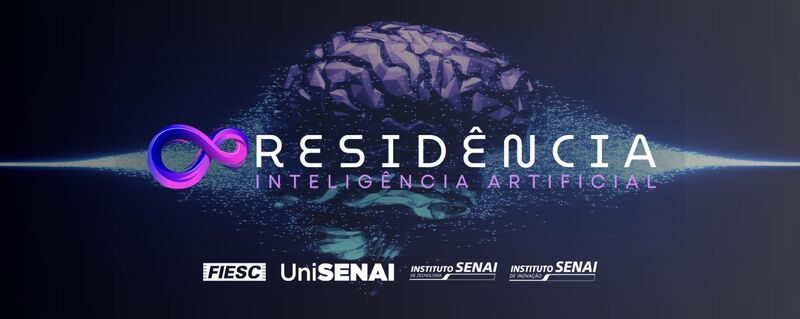

<h1><b>Pós-Graduação em Inteligência Artificial Aplicada</b></h1>



<h2>Unidade Curricular : Aprendizado de Máquina</h2>



<h2>Professor : Giancarlo Marchesini</h2>


# Aula 2 — CRISP-DM: Metodologia, Análise Exploratória e Estatística
### Pós-graduação em IA Aplicada

**Pré-requisito:** Aula 1 — Aprendizado Supervisionado x Não Supervisionado

---

### O que esta aula cobre (e o que fica para depois)

Hoje vamos entender a metodologia **CRISP-DM completa**, do início ao fim, em teoria. Na prática, porém, vamos trabalhar **apenas até a Fase 3 (Preparação dos Dados)** — com foco total em **análise exploratória e estatística descritiva**.

### Como este notebook explica o código

Como a turma ainda está começando em Python, cada célula de código vem acompanhada de:
1. Uma explicação **antes**, dizendo o que vamos fazer e por quê.
2. **Comentários em toda linha de código** (o texto depois do `#`), explicando o que aquela linha específica está fazendo.
3. Quando uma função do Python aparece pela primeira vez (como `.mean()`, `.loc[]`, `plt.subplots()`), há uma caixa de **"Conceito"** explicando como ela funciona, antes do código que a usa.

Não tem problema ler um comentário e não entender de primeira — o objetivo é vocês conseguirem, ao final da aula, ler o código de cima a baixo e explicar em voz alta o que cada linha faz.

### Agenda sugerida (para o professor cronometrar)

| Bloco | Conteúdo | Tempo aprox. |
|---|---|---|
| 1 | Revisão da Aula 1 + por que metodologia importa | 10 min |
| 2 | Teoria: as 6 fases do CRISP-DM (completa) | 20 min |
| 3 | Armadilhas na análise exploratória (com código comentado) | 20 min |
| 4 | Exemplo completo — Cooperativa de Crédito (Fases 1 a 3) | 40 min |
| 5 | Exercício guiado 1 — Transporte | 15 min |
| 6 | Exercício guiado 2 — Saúde | 15 min |
| 7 | Exercício guiado 3 — Indústria/Agroindústria ** | 10 min |
| 8 | Correção coletiva com gabaritos + fechamento | 10 min |

> ▶️ **Como usar este notebook no Google Colab:** `Arquivo > Fazer upload de notebook`, envie este `.ipynb` e execute as células em ordem (Shift+Enter).

> ⚠️ Sempre que um número ou estatística de mercado aparecer neste material sem uma fonte verificável específica, ele estará sinalizado como estimativa — tratem como referência de ordem de grandeza, não como dado citável sem checagem.


## 0. Rápida conexão com a Aula 1

Na aula passada vimos dois grandes tipos de aprendizado de máquina:

| Tipo | O que é | Exemplo (que vamos só *cogitar* hoje, sem treinar ainda) |
|---|---|---|
| **Supervisionado** | Aprende a partir de exemplos rotulados (temos a "resposta certa" no histórico) | Prever se um associado da cooperativa vai ficar inadimplente (sim/não) |
| **Não supervisionado** | Encontra padrões em dados **sem** rótulo | Agrupar pacientes por perfil de risco, sem saber de antemão os grupos |

Hoje, ao explorarmos os dados de cada exemplo, vamos identificar **qual desses dois tipos** cada problema seria — mas o treinamento em si dos modelos fica para as próximas aulas.


## 1. Por que uma metodologia?

Uma crença comum entre quem está começando em IA é: *"o difícil é treinar o modelo"*. Na prática, na maioria dos projetos reais, **treinar o modelo é a parte relativamente fácil**. O que separa um projeto que gera valor de um projeto que morre no notebook do cientista de dados costuma ser:

- Resolver o problema errado (com muita precisão).
- Descobrir tarde demais que os dados não sustentam a pergunta feita.
- Nunca ter explorado os dados a fundo, e só perceber problemas de qualidade quando o "modelo" (ainda inexistente) já deveria estar pronto.

> ⚠️ Sinalizando incerteza: é comum ver, em relatórios de consultorias e pesquisas de mercado, a afirmação de que a maioria dos projetos de ciência de dados/IA nunca chega à produção. Não tenho uma fonte verificada e atual (2026) para citar um percentual exato aqui — tratem como estimativa de ordem de grandeza, não como dado citável sem checagem.

O CRISP-DM existe justamente para reduzir esse risco: ele obriga o time a validar, fase a fase, se o projeto ainda faz sentido — **antes** de investir semanas construindo algo sobre uma base mal compreendida.

### CRISP-DM não é a única metodologia — mas é a mais adotada
Existem variações como **SEMMA** (SAS) ou processos internos de empresas (ex. Microsoft TDSP). O CRISP-DM continua sendo a referência mais citada em pesquisas com praticantes de dados por ser **agnóstica de ferramenta e de indústria** — funciona tanto para uma cooperativa de crédito quanto para uma linha de produção industrial.


## 2. As 6 fases do CRISP-DM

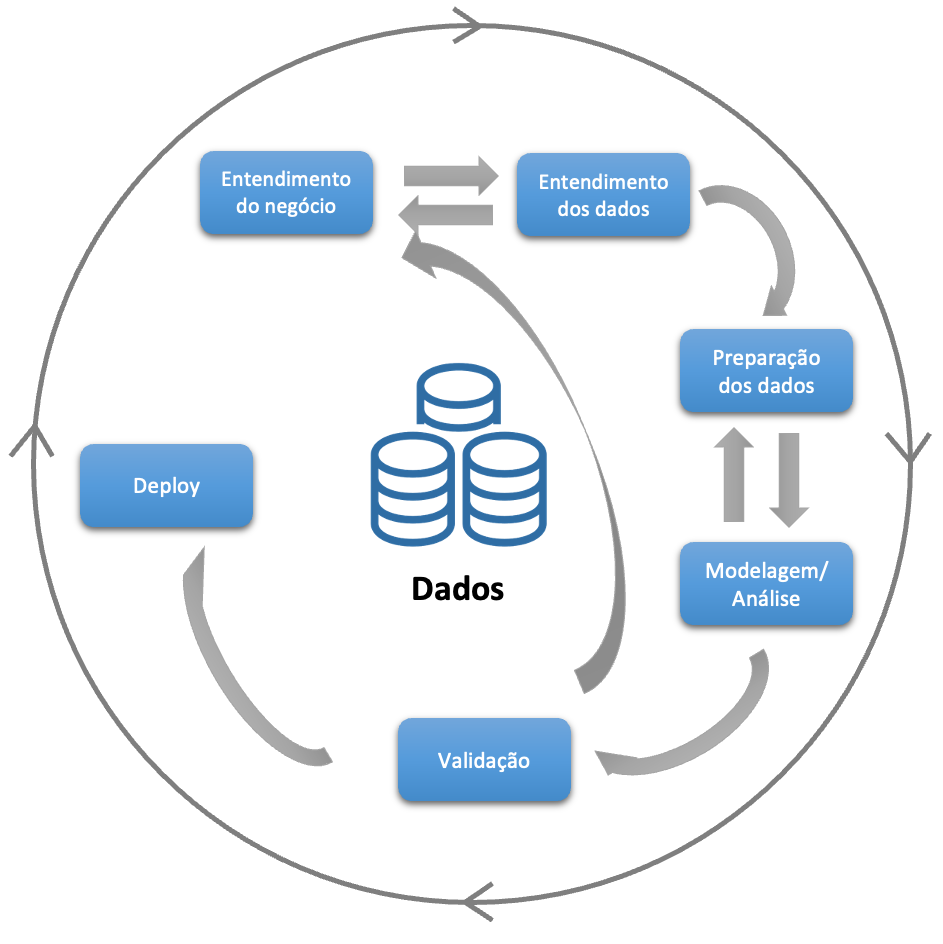

As setas de retorno são o ponto mais importante: CRISP-DM não é uma linha reta. É normal, ao preparar os dados, perceber que a pergunta de negócio precisa ser ajustada; ou, ao avaliar o modelo (nas próximas aulas), descobrir que faltam dados e ser preciso voltar à fase 2.

### 2.1 Fase 1 — Entendimento do Negócio (*Business Understanding*)
- Qual é a pergunta real? ("Reduzir inadimplência" não é uma pergunta de IA; "identificar quais características estão associadas a maior risco de atraso" já é.)
- Qual é o critério de sucesso, técnico e de negócio?
- Quem vai usar o resultado, e como?
- Existe restrição regulatória ou ética relevante?

**🚩 Armadilhas comuns:** pular direto para "analisar os dados" sem escrever a pergunta com clareza; confundir métrica técnica com objetivo de negócio; não envolver quem conhece a operação; definir sucesso de forma vaga demais.

### 2.2 Fase 2 — Entendimento dos Dados (*Data Understanding*)
**É aqui que a análise exploratória e a estatística descritiva entram — o foco prático de hoje.**
- Quais fontes de dados existem?
- Qualidade: há dados faltantes? Duplicados? Desatualizados?
- Estatísticas descritivas, distribuições, correlações, valores atípicos.
- Como os dados foram coletados? (viés de coleta)

**🚩 Armadilhas comuns:** assumir que os dados estão limpos sem checar; ignorar viés de coleta; tratar erro de sistema como dado real; confundir correlação com causalidade (Seção 3); vazamento de informação do futuro.

### 2.3 Fase 3 — Preparação dos Dados (*Data Preparation*)
Normalmente a fase que consome mais tempo em um projeto real.
- Tratamento de valores faltantes
- Remoção de duplicados
- Tratamento de outliers usando critérios estatísticos (ex. IQR)
- *(Codificação de categorias e padronização de escala, específicas para um algoritmo, ficam para quando começarmos a modelar.)*

> ⚠️ Sinalizando incerteza: a regra informal de que a Preparação de Dados consome "60-80% do tempo" de um projeto é senso comum de mercado, sem uma fonte primária exata que eu possa citar aqui.

**🚩 Armadilhas comuns:** preencher faltantes sem entender a causa; remover outliers sem investigar se são erro ou caso real; não documentar as decisões.

### 2.4 Fase 4 — Modelagem (*Modeling*)
Escolher o algoritmo — supervisionado ou não supervisionado (conexão com a Aula 1) — e treiná-lo. É comum voltar à Fase 3 para ajustar os dados conforme o algoritmo exige.

**🚩 Armadilhas:** escolher o algoritmo "da moda" sem necessidade; *overfitting* (o modelo decora o treino); não comparar com um baseline simples.

### 2.5 Fase 5 — Avaliação (*Evaluation*)
Confrontar o resultado com o objetivo de negócio da Fase 1.

**🚩 Armadilha mais citada:** o "paradoxo da acurácia" em bases desbalanceadas — algo que já conseguimos enxergar hoje, só olhando a proporção das classes na análise exploratória.

### 2.6 Fase 6 — Implantação (*Deployment*)
Colocar o resultado para uso real, com monitoramento e plano de manutenção.

**🚩 Armadilha mais citada:** **"o projeto morre no notebook"** — nunca chega a ser usado de verdade.

> 📌 A análise exploratória não é uma etapa burocrática antes do que importa — ela **é** onde a maior parte dos problemas de um projeto de IA é descoberta ou evitada.


## 3. Armadilhas que já aparecem na análise exploratória

Vamos demonstrar com código duas armadilhas que acontecem *antes* de qualquer modelo existir.


### Conceito: bibliotecas e `import`

Python, sozinho, não sabe fazer conta com tabelas de dados ou desenhar gráficos — isso vem de **bibliotecas** (pacotes de código pronto, escrito por outras pessoas, que podemos reaproveitar). Usamos `import` para "carregar" uma biblioteca antes de usá-la, e `as` para dar um apelido curto a ela (assim escrevemos `pd.algumacoisa()` em vez do nome completo toda vez).

As quatro que vamos usar hoje:
- **`numpy`** (apelido `np`): trabalha com números e cálculos matemáticos/estatísticos, e também gera dados aleatórios (útil para simular uma base de exemplo).
- **`pandas`** (apelido `pd`): organiza dados em formato de tabela (linhas e colunas), parecido com uma planilha — é a ferramenta central da análise exploratória.
- **`matplotlib.pyplot`** (apelido `plt`): desenha gráficos básicos (histogramas, boxplots).
- **`seaborn`** (apelido `sns`): desenha gráficos estatísticos mais elaborados (como o mapa de calor de correlação) de forma mais simples que o matplotlib puro.


In [ ]:
# import numpy: carrega a biblioteca numpy e a apelida de "np" para digitarmos menos
import numpy as np

# import pandas: carrega a biblioteca pandas e a apelida de "pd"
import pandas as pd

# import matplotlib.pyplot: carrega só a "parte de gráficos" do matplotlib, apelidada de "plt"
import matplotlib.pyplot as plt

# import seaborn: carrega o seaborn, apelidado de "sns" (apelido tradicional da comunidade)
import seaborn as sns

# plt.rcParams é um "dicionário de configurações padrão" do matplotlib.
# Aqui estamos dizendo: todo gráfico que desenharmos vai ter, por padrão,
# 7 polegadas de largura por 4 de altura - só para os gráficos ficarem
# de um tamanho legível na tela, sem precisarmos repetir isso toda vez.
plt.rcParams["figure.figsize"] = (7, 4)

# sns.set_style define a aparência visual padrão dos gráficos do seaborn.
# "whitegrid" desenha um fundo branco com linhas de grade discretas,
# o que facilita ler valores nos eixos.
sns.set_style("whitegrid")

# print() só imprime um texto na tela, para confirmarmos que rodou sem erro
print("Bibliotecas carregadas.")


Bibliotecas carregadas.




```
# Isto está formatado como código
```

### Armadilha — Média enganosa por causa de valores atípicos (*outliers*)

**Conceito: Média, Mediana**
- **Média**: soma de todos os valores dividida pela quantidade de valores. É sensível a valores extremos.
- **Mediana**: o valor do meio quando os dados são ordenados. Não é puxada por valores extremos da mesma forma.

**Conceito: `pd.Series`**
Uma `pd.Series` é a estrutura mais simples do pandas: uma coluna única de valores (parecido com uma lista do Python, mas com recursos estatísticos prontos, como `.mean()` e `.median()`).


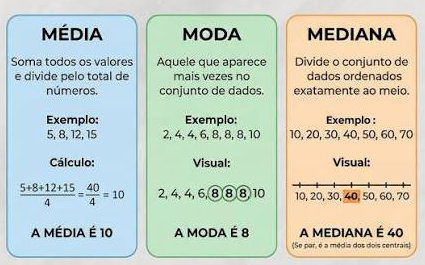

In [ ]:
# pd.Series([...]) cria uma "coluna" de dados a partir de uma lista de números
# Aqui simulamos a renda de 10 associados de uma cooperativa
renda_exemplo = pd.Series([2200, 2500, 2800, 3000, 3100, 3300, 3400, 3600, 3900, 42000])
# repare no último valor, 42000: é bem mais alto que os demais, de propósito

# .mean() soma todos os 10 valores e divide por 10 -> calcula a média
# o f"..." antes das aspas cria uma "f-string": um texto onde podemos inserir
# valores de variáveis dentro de chaves {}; ":,.2f" formata o número com
# separador de milhar e 2 casas decimais
print(f"Média:   R$ {renda_exemplo.mean():,.2f}")

# .median() ordena os 10 valores e pega o do meio (a média dos dois centrais,
# já que temos uma quantidade par de valores) -> calcula a mediana
print(f"Mediana: R$ {renda_exemplo.median():,.2f}")


Média:   R$ 6,980.00
Mediana: R$ 3,200.00


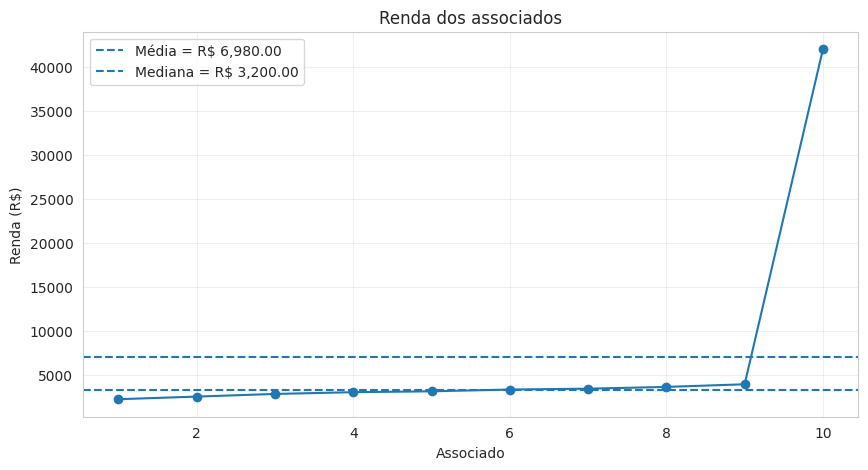

In [ ]:
# matplotlib já foi importado (apelido plt) na célula das bibliotecas, lá em cima
# Calcula média e mediana
media = renda_exemplo.mean()
mediana = renda_exemplo.median()


# ============================================================
# GRÁFICO 1 — VALORES INDIVIDUAIS
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(renda_exemplo) + 1),
    renda_exemplo,
    "o-"
)

plt.axhline(
    media,
    linestyle="--",
    label=f"Média = R$ {media:,.2f}"
)

plt.axhline(
    mediana,
    linestyle="--",
    label=f"Mediana = R$ {mediana:,.2f}"
)

plt.title("Renda dos associados")
plt.xlabel("Associado")
plt.ylabel("Renda (R$)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

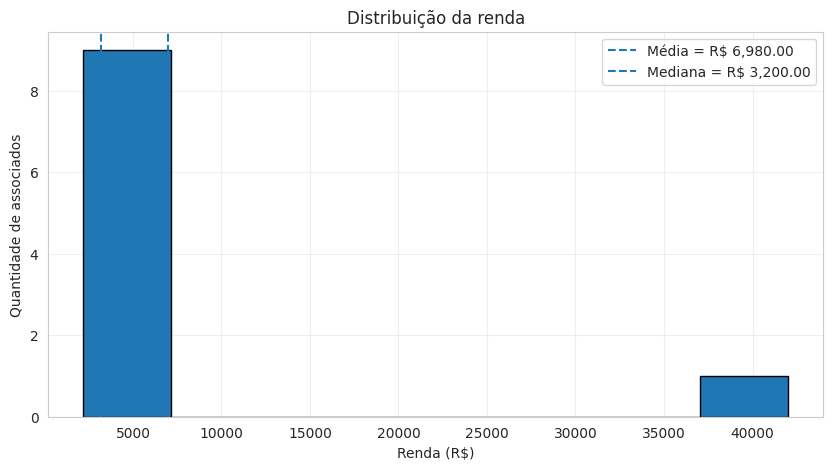

In [ ]:
# ============================================================
# GRÁFICO 2 — HISTOGRAMA
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    renda_exemplo,
    bins=8,
    edgecolor="black"
)

plt.axvline(
    media,
    linestyle="--",
    label=f"Média = R$ {media:,.2f}"
)

plt.axvline(
    mediana,
    linestyle="--",
    label=f"Mediana = R$ {mediana:,.2f}"
)

plt.title("Distribuição da renda")
plt.xlabel("Renda (R$)")
plt.ylabel("Quantidade de associados")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

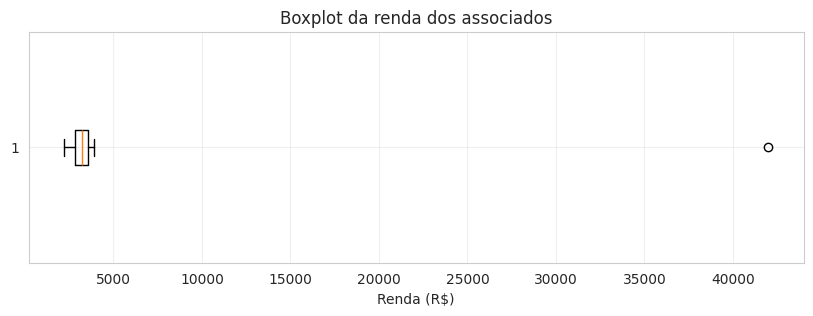

In [ ]:
# ============================================================
# GRÁFICO 3 — BOXPLOT
# ============================================================

plt.figure(figsize=(10, 3))

plt.boxplot(renda_exemplo, vert=False)

plt.title("Boxplot da renda dos associados")
plt.xlabel("Renda (R$)")
plt.grid(alpha=0.3)

plt.show()

**O que aconteceu:** o valor R\$ 42.000 fez a **média** subir para um patamar que não representa bem "o associado típico" — nove em cada dez ganham entre R\$ 2.200 e R\$ 3.900. A **mediana** continua representando melhor o centro real dos dados.

**Armadilha na prática:** um relatório que dissesse só *"a renda média é R\$ ~7.780"* daria uma impressão distorcida. Por isso olhamos média **e** mediana lado a lado.


## 4. Mão na massa: CRISP-DM (Fases 1 a 3) — Cooperativa de Crédito

Vamos aplicar as três primeiras fases do CRISP-DM em um problema de uma cooperativa de crédito: **entender o perfil dos associados e o comportamento de atraso**, sem treinar nenhum modelo ainda.


### 4.1 Fase 1 — Entendimento do Negócio

**Contexto simulado:** uma cooperativa de crédito percebeu aumento na inadimplência e quer entender melhor o perfil dos associados antes de decidir os próximos passos.

- **Pergunta de negócio:** "Como reduzir a inadimplência?"
- **Pergunta traduzida para análise:** "Quais características dos associados parecem estar associadas a maior risco de atraso, e a base de dados está pronta para uma análise mais aprofundada no futuro?"
- **Tipo de aprendizado futuro (conexão com a Aula 1):** **supervisionado** — existe um histórico rotulado (atrasou / não atrasou).
- **Critério de sucesso de hoje:** uma base limpa, documentada, e observações estatísticas que sustentem decisões futuras.


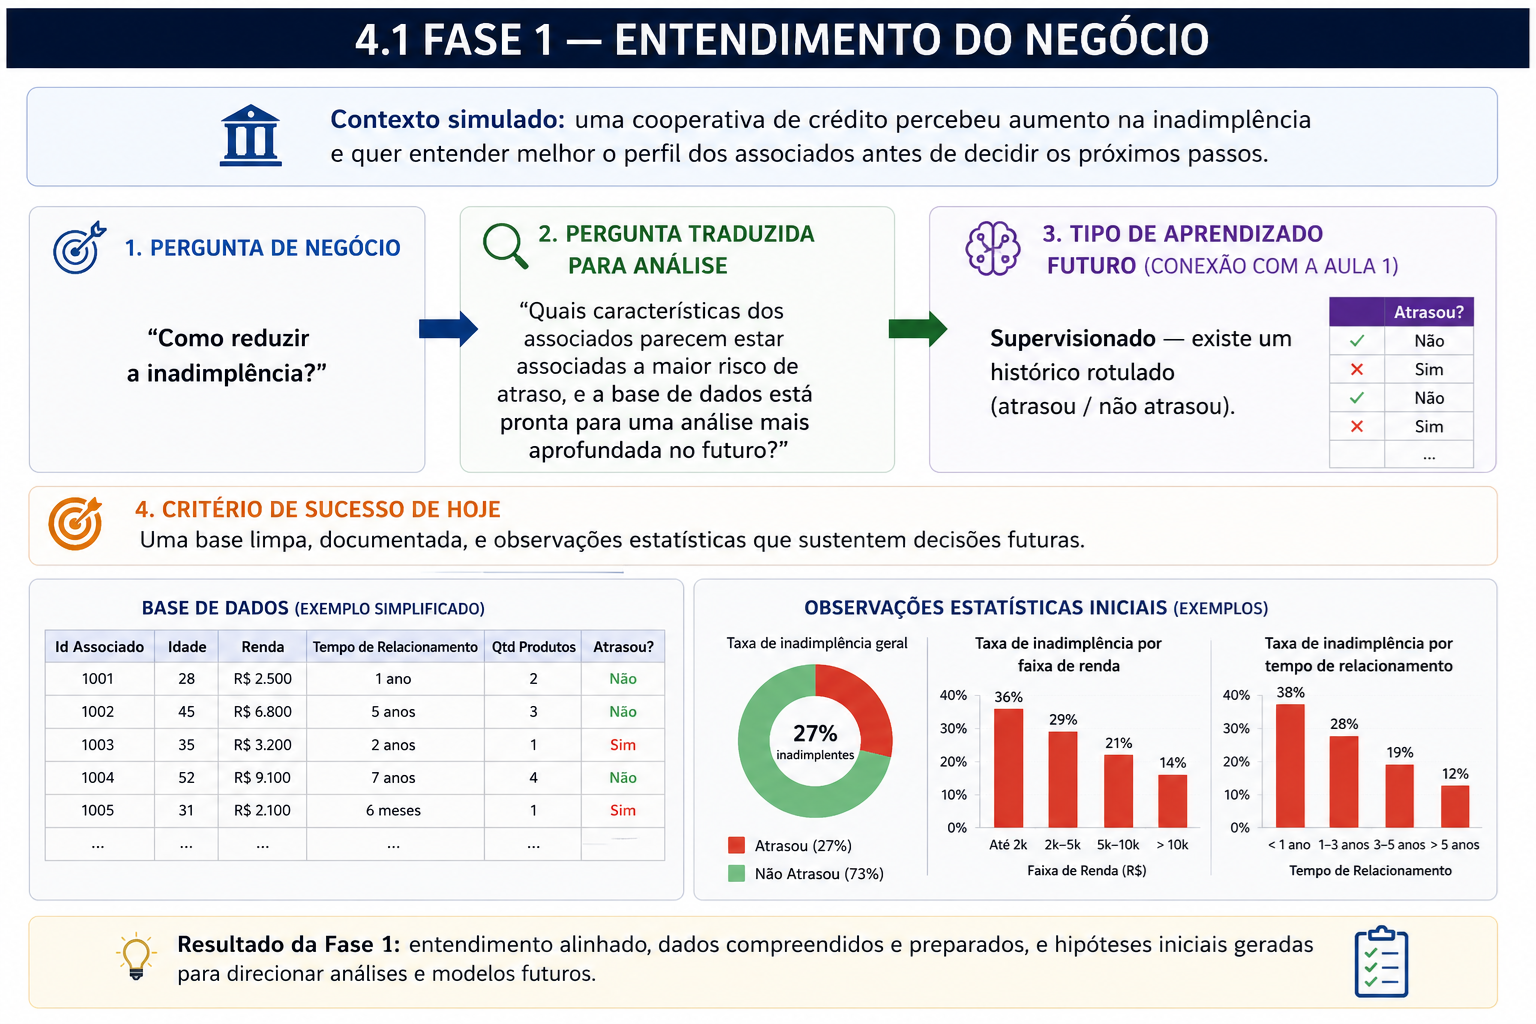

### 4.2 Fase 2 — Entendimento dos Dados

Vamos gerar uma base sintética (simulada) de associados. Em um projeto real, essa base viria do sistema de gestão de crédito da cooperativa; como não temos acesso a dados reais, criamos uma artificialmente — de propósito, com valores faltantes, duplicados e outliers, para praticar a limpeza depois.

**Conceito: `np.random.poisson()`**
Sorteia números inteiros seguindo a distribuição de Poisson — útil para simular **contagens de eventos raros**, como "quantas vezes um associado atrasou nos últimos 12 meses" (a maioria terá 0 ou 1 atraso; poucos terão vários).

**Conceito: `.clip(mínimo, máximo)`**
"Corta" (limita) os valores de uma lista de números para não passarem de um mínimo ou máximo — por exemplo, impedir que uma renda simulada saia negativa por acaso do sorteio aleatório.


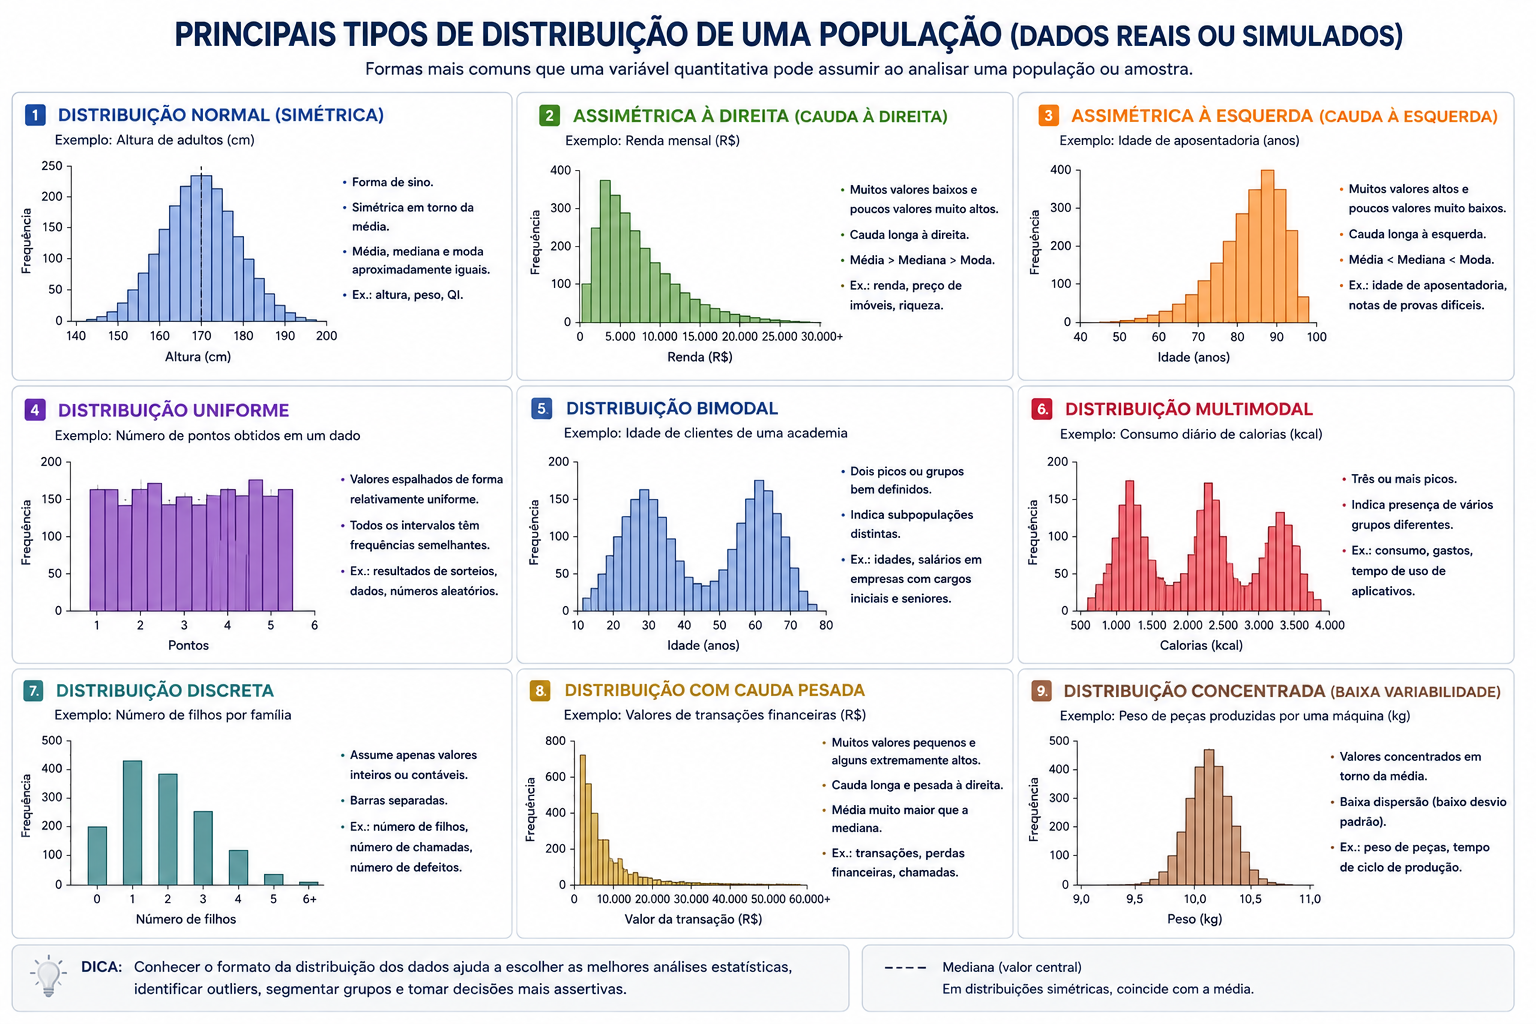

In [ ]:
# Fixamos a seed para o resultado ser sempre o mesmo para toda a turma
np.random.seed(42)

# n guarda quantos associados fictícios vamos simular
n = 800

# np.random.normal(4500, 1800, n) sorteia 800 valores de renda seguindo uma
# distribuição normal com média R$4.500 e desvio-padrão R$1.800
# .clip(1200, 20000) garante que nenhum valor sorteado fique abaixo de
# R$1.200 nem acima de R$20.000 (só para manter os valores plausíveis)
renda_mensal = np.random.normal(4500, 1800, n).clip(1200, 20000)

# np.random.randint(1, 180, n) sorteia 800 números inteiros entre 1 e 179,
# simulando "há quantos meses o associado é cooperado"
tempo_relacionamento_meses = np.random.randint(1, 180, n)

# mesma lógica da renda, mas para o valor da parcela do empréstimo
valor_parcela = np.random.normal(650, 300, n).clip(80, 4000)

# np.random.poisson(0.7, n) simula, para cada associado, quantos atrasos
# ele teve nos últimos 12 meses (a maioria vai ter 0, poucos vão ter 2, 3...)
n_atrasos_ultimos_12m = np.random.poisson(0.7, n)

# um "score interno" fictício de 200 a 1000, simulando uma pontuação de
# crédito que a cooperativa já calcularia internamente
score_interno = np.random.normal(600, 120, n).clip(200, 1000)

# np.random.choice([0, 1], n, p=[0.35, 0.65]) sorteia, para cada associado,
# se ele possui conta corrente na cooperativa (1) ou não (0) - com 65% de
# chance de ter conta corrente
possui_conta_corrente = np.random.choice([0, 1], n, p=[0.35, 0.65])

print("Variáveis simuladas.")


Variáveis simuladas.


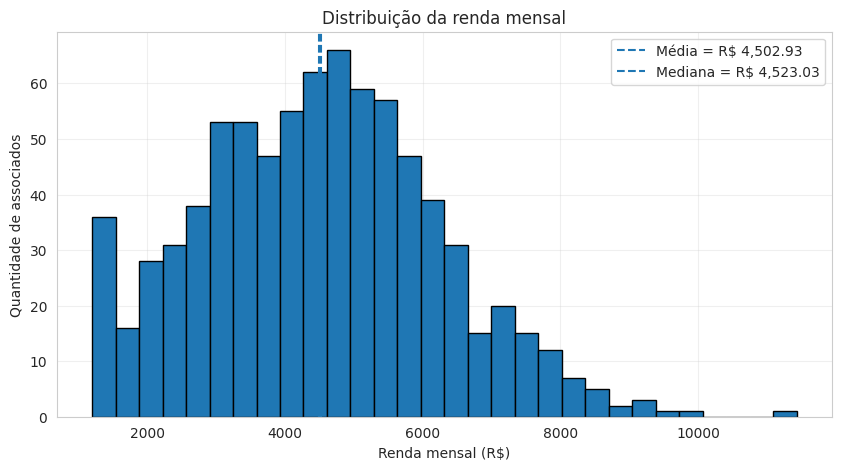

In [ ]:
# numpy (np), pandas (pd) e matplotlib.pyplot (plt) já foram importados
# na célula de bibliotecas, no início do notebook - não precisamos
# importar de novo, só reaproveitar os apelidos já criados

# ============================================================
# 1. DISTRIBUIÇÃO DA RENDA MENSAL
# ============================================================


# Cria uma nova figura para o gráfico.
#
# figsize=(10, 5) define o tamanho da figura:
# 10 → largura
# 5  → altura
#
# Os valores são medidos em polegadas.
plt.figure(figsize=(10, 5))


# Cria um histograma.
#
# Um histograma mostra como os valores estão distribuídos.
# Neste caso, queremos saber como as rendas dos associados
# estão distribuídas.
plt.hist(

    # Dados que serão utilizados no histograma.
    # Aqui estamos passando a variável que contém
    # as rendas dos associados.
    renda_mensal,

    # Divide os valores em 30 intervalos (bins).
    #
    # Quanto maior o número de bins, mais detalhada será
    # a distribuição apresentada no gráfico.
    bins=30,

    # Desenha uma borda preta ao redor de cada barra.
    # Isso facilita a visualização das barras.
    edgecolor="black"
)


# ============================================================
# 2. CALCULANDO A MÉDIA E A MEDIANA
# ============================================================


# Calcula a média da renda.
#
# np.mean() recebe todos os valores de renda,
# soma esses valores e divide pela quantidade
# de associados.
#
# O resultado é armazenado na variável "media".
media = np.mean(renda_mensal)


# Calcula a mediana da renda.
#
# np.median() organiza os valores e identifica
# o valor que está no centro da distribuição.
#
# A mediana é menos sensível a valores extremos
# do que a média.
mediana = np.median(renda_mensal)


# ============================================================
# 3. DESENHANDO A LINHA DA MÉDIA
# ============================================================


# plt.axvline() cria uma linha vertical no gráfico.
#
# Como a renda está no eixo X, a linha será posicionada
# no valor correspondente à média.
plt.axvline(

    # Posição da linha no eixo X.
    # Aqui estamos dizendo:
    # "desenhe a linha exatamente no valor da média".
    media,

    # Define a linha como tracejada.
    # "--" significa linha tracejada.
    linestyle="--",

    # Texto que aparecerá na legenda.
    #
    # O "f" antes das aspas transforma o texto em uma
    # f-string, permitindo colocar o valor da variável
    # "media" dentro do texto usando {media}.
    #
    # ":,.2f" significa:
    # ,  → separador de milhares
    # .2 → duas casas decimais
    # f  → formato numérico decimal
    label=f"Média = R$ {media:,.2f}"
)


# ============================================================
# 4. DESENHANDO A LINHA DA MEDIANA
# ============================================================


# Cria uma segunda linha vertical.
#
# Desta vez, a linha será posicionada no valor da mediana.
plt.axvline(

    # Posição da linha no eixo X.
    mediana,

    # Também utilizaremos uma linha tracejada.
    linestyle="--",

    # Texto que aparecerá na legenda.
    #
    # Novamente utilizamos uma f-string para inserir
    # automaticamente o valor calculado da mediana.
    label=f"Mediana = R$ {mediana:,.2f}"
)


# ============================================================
# 5. CONFIGURANDO O TÍTULO
# ============================================================


# Define o título que aparecerá na parte superior do gráfico.
plt.title(
    "Distribuição da renda mensal"
)


# ============================================================
# 6. CONFIGURANDO O EIXO X
# ============================================================


# Define o nome do eixo X.
#
# O eixo X representa os valores de renda dos associados.
plt.xlabel(
    "Renda mensal (R$)"
)


# ============================================================
# 7. CONFIGURANDO O EIXO Y
# ============================================================


# Define o nome do eixo Y.
#
# O eixo Y representa quantos associados estão
# dentro de cada faixa de renda.
plt.ylabel(
    "Quantidade de associados"
)


# ============================================================
# 8. MOSTRANDO A LEGENDA
# ============================================================


# Exibe a legenda do gráfico.
#
# A legenda mostrará:
# - Média
# - Mediana
#
# Esses textos foram definidos anteriormente
# usando o parâmetro "label".
plt.legend()


# ============================================================
# 9. ADICIONANDO UMA GRADE
# ============================================================


# Adiciona linhas de grade ao gráfico.
#
# alpha=0.3 define a transparência da grade.
# O valor varia de 0 a 1:
#
# 0   → totalmente transparente
# 1   → totalmente visível
plt.grid(alpha=0.3)


# ============================================================
# 10. EXIBINDO O GRÁFICO
# ============================================================


# Exibe o gráfico na tela.
#
# Sem plt.show(), dependendo do ambiente,
# o gráfico pode não ser apresentado corretamente.
plt.show()




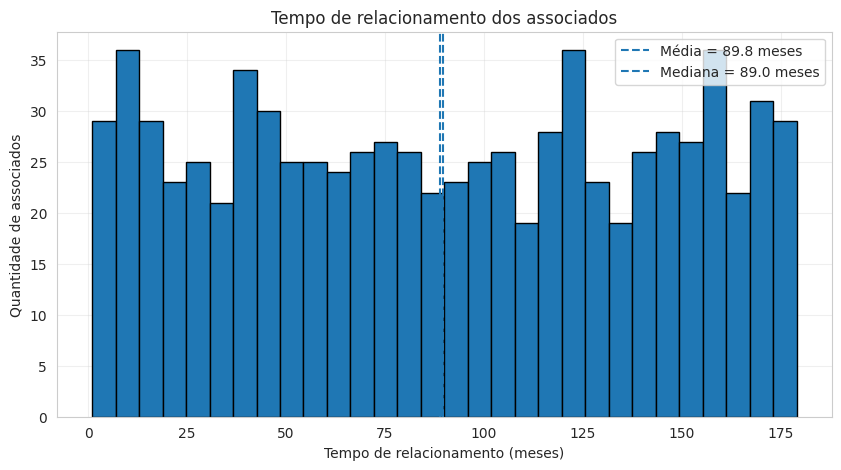

In [ ]:
# ============================================================
# 2. TEMPO DE RELACIONAMENTO
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    tempo_relacionamento_meses,
    bins=30,
    edgecolor="black"
)

media = np.mean(tempo_relacionamento_meses)
mediana = np.median(tempo_relacionamento_meses)

plt.axvline(
    media,
    linestyle="--",
    label=f"Média = {media:.1f} meses"
)

plt.axvline(
    mediana,
    linestyle="--",
    label=f"Mediana = {mediana:.1f} meses"
)

plt.title("Tempo de relacionamento dos associados")
plt.xlabel("Tempo de relacionamento (meses)")
plt.ylabel("Quantidade de associados")
plt.legend()
plt.grid(alpha=0.3)

plt.show()




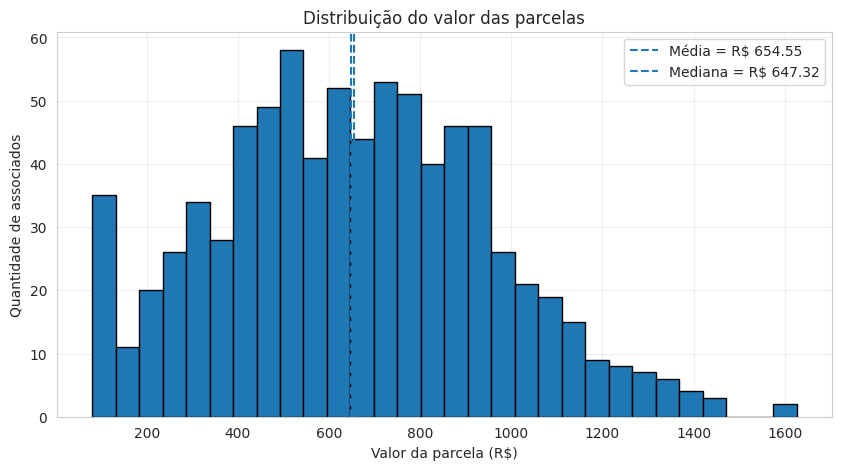

In [ ]:
# ============================================================
# 3. DISTRIBUIÇÃO DO VALOR DA PARCELA
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    valor_parcela,
    bins=30,
    edgecolor="black"
)

media = np.mean(valor_parcela)
mediana = np.median(valor_parcela)

plt.axvline(
    media,
    linestyle="--",
    label=f"Média = R$ {media:,.2f}"
)

plt.axvline(
    mediana,
    linestyle="--",
    label=f"Mediana = R$ {mediana:,.2f}"
)

plt.title("Distribuição do valor das parcelas")
plt.xlabel("Valor da parcela (R$)")
plt.ylabel("Quantidade de associados")
plt.legend()
plt.grid(alpha=0.3)

plt.show()




**Conceito: histograma para uma variável de contagem (poucos valores inteiros)**

`n_atrasos_ultimos_12m` só assume valores inteiros pequenos (0, 1, 2, 3...), diferente da renda ou do score, que são contínuos. Por isso o histograma usa alguns parâmetros extras:
- `bins=range(mínimo, máximo + 2)`: em vez de dividir os dados em faixas arbitrárias, cria uma faixa para **cada valor inteiro** possível (o "+2" garante que o último valor também caiba numa faixa).
- `align="left"`: alinha cada barra exatamente sobre o número inteiro que ela representa (em vez de centralizada entre dois números).
- `rwidth=0.8`: deixa um pequeno espaço entre as barras (90% a 100% deixaria as barras coladas), facilitando enxergar que são contagens discretas, e não uma faixa contínua.


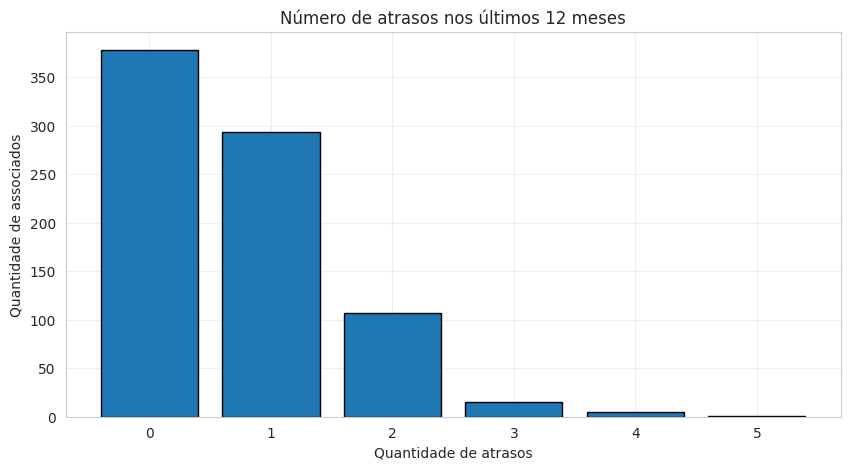

In [ ]:
# ============================================================
# 4. NÚMERO DE ATRASOS NOS ÚLTIMOS 12 MESES
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    n_atrasos_ultimos_12m,
    bins=range(
        n_atrasos_ultimos_12m.min(),
        n_atrasos_ultimos_12m.max() + 2
    ),
    align="left",
    rwidth=0.8,
    edgecolor="black"
)

plt.title("Número de atrasos nos últimos 12 meses")
plt.xlabel("Quantidade de atrasos")
plt.ylabel("Quantidade de associados")
plt.grid(alpha=0.3)

plt.show()




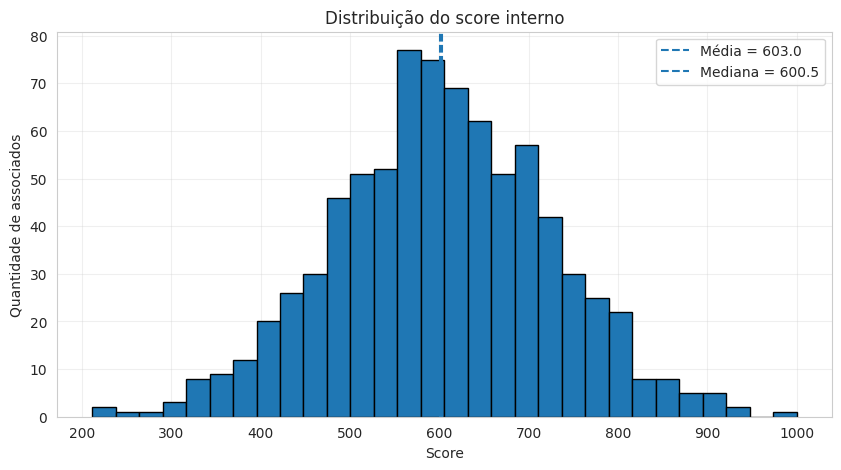

In [ ]:
# ============================================================
# 5. DISTRIBUIÇÃO DO SCORE INTERNO
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    score_interno,
    bins=30,
    edgecolor="black"
)

media = np.mean(score_interno)
mediana = np.median(score_interno)

plt.axvline(
    media,
    linestyle="--",
    label=f"Média = {media:.1f}"
)

plt.axvline(
    mediana,
    linestyle="--",
    label=f"Mediana = {mediana:.1f}"
)

plt.title("Distribuição do score interno")
plt.xlabel("Score")
plt.ylabel("Quantidade de associados")
plt.legend()
plt.grid(alpha=0.3)

plt.show()




**Conceito: gráfico de barras para uma variável categórica, e `.value_counts()`**

`possui_conta_corrente` não é uma quantidade — é uma categoria (0 = não possui, 1 = possui). Para esse tipo de variável, um histograma não faz muito sentido; um **gráfico de barras** é mais apropriado, com uma barra por categoria.

- `.value_counts()` conta quantas vezes cada valor aparece na coluna (já vimos essa função antes, na proporção de atraso).
- `.sort_index()` ordena o resultado pelos próprios valores (0 antes de 1), em vez de ordenar pela quantidade — assim a barra "Não possui" (0) sempre aparece antes de "Possui" (1), independente de qual grupo é maior.
- `plt.bar(categorias, valores)` desenha uma barra para cada categoria, com a altura correspondente ao valor.


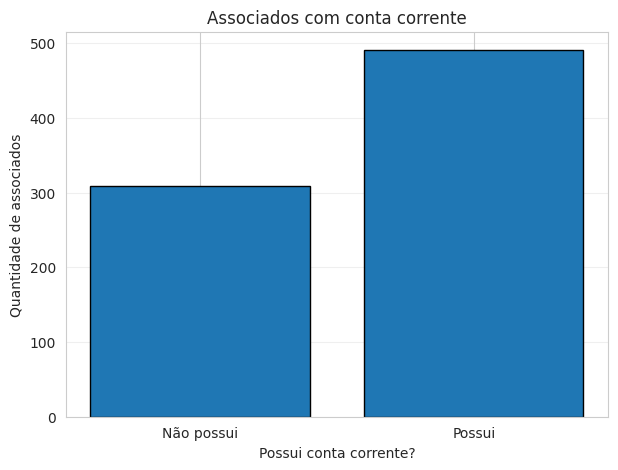

In [ ]:
# ============================================================
# 6. POSSUI CONTA CORRENTE?
# ============================================================

# Conta quantos associados possuem ou não conta corrente.
#
# 0 = Não possui
# 1 = Possui

contagem_conta = pd.Series(
    possui_conta_corrente
).value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Não possui", "Possui"],
    contagem_conta.values,
    edgecolor="black"
)

plt.title("Associados com conta corrente")
plt.xlabel("Possui conta corrente?")
plt.ylabel("Quantidade de associados")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Gerando o rótulo "atrasou_proxima_parcela"

Para o exemplo fazer sentido, precisamos simular **se cada associado atrasou ou não** — e essa simulação precisa ter alguma relação com as variáveis acima (senão a análise exploratória não teria nada de interessante para encontrar depois).

**Conceito: transformar uma "pontuação de risco" em uma probabilidade**
Vamos calcular uma combinação matemática simples das variáveis (uma "pontuação de risco"), e depois usar uma função matemática (a função logística, ou "sigmoide") para transformar essa pontuação em um número entre 0 e 1 — ou seja, em uma **probabilidade**. Isso é só um recurso para a simulação funcionar; **não é** algo que vocês precisam saber fazer de cor, é só a "receita" que usamos para fabricar dados de exemplo realistas.

**Conceito: `np.random.binomial(1, probabilidade, quantidade)`**
Para cada probabilidade da lista, sorteia um resultado 1 (aconteceu) ou 0 (não aconteceu) — como jogar uma moeda viciada de acordo com aquela chance, uma vez para cada associado.


In [ ]:
# Calculamos uma "pontuação de risco" combinando as variáveis: valores
# positivos empurram a pontuação para cima (mais risco), valores negativos
# empurram para baixo (menos risco) - os números (0.00003, 0.0006 etc.)
# foram escolhidos manualmente só para a simulação ficar realista
prob_atraso = (
    0.35
    - 0.00003 * renda_mensal            # quanto maior a renda, menor o risco
    - 0.0006 * score_interno            # quanto maior o score, menor o risco
    + 0.06 * n_atrasos_ultimos_12m      # quanto mais atrasos no passado, maior o risco
    + 0.00025 * valor_parcela           # parcela mais alta, maior o risco
    - 0.10 * possui_conta_corrente      # ter conta corrente reduz um pouco o risco
)

# Aplicamos a função sigmoide (1 / (1 + e^-x)) para transformar a pontuação
# em um número entre 0 e 1 (uma probabilidade). O "-1.2" desloca a curva
# para a inadimplência ficar perto de 20-25% da base - mais realista que 50/50
prob_atraso = 1 / (1 + np.exp(-(prob_atraso * 4 - 1.2)))

# np.random.binomial(1, prob_atraso) sorteia, para cada associado, um 0 ou 1
# de acordo com a probabilidade calculada para ele - esse é o nosso rótulo final
atrasou_proxima_parcela = np.random.binomial(1, prob_atraso)

print("Rótulo 'atrasou_proxima_parcela' gerado.")


Rótulo 'atrasou_proxima_parcela' gerado.


### Conceito: `pd.DataFrame` (a tabela principal)

Um `DataFrame` é a estrutura central do pandas: uma tabela com linhas e colunas, como uma planilha do Excel. Criamos um a partir de um **dicionário Python**: cada chave (`"renda_mensal"`, `"tempo_relacionamento_meses"`...) vira o nome de uma coluna, e a lista de valores associada a ela vira o conteúdo da coluna.


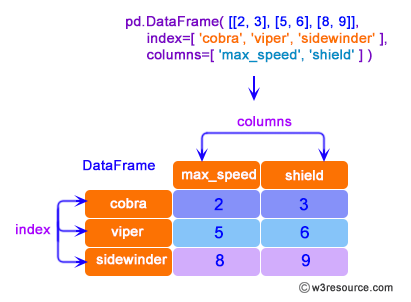

In [ ]:
# Reunimos todas as variáveis simuladas em uma única tabela (DataFrame)
df = pd.DataFrame({
    "renda_mensal": renda_mensal.round(2),                    # .round(2) arredonda para 2 casas decimais
    "tempo_relacionamento_meses": tempo_relacionamento_meses,
    "valor_parcela": valor_parcela.round(2),
    "n_atrasos_ultimos_12m": n_atrasos_ultimos_12m,
    "score_interno": score_interno.round(0),                  # arredonda para número inteiro (0 casas decimais)
    "possui_conta_corrente": possui_conta_corrente,
    "atrasou_proxima_parcela": atrasou_proxima_parcela,
})

print("Tabela criada.")


Tabela criada.


In [ ]:
df.head()  # mostra só as 5 primeiras linhas, para não poluir a tela com as 800 linhas inteiras

### Simulando problemas reais de qualidade de dados

Bases de dados reais quase sempre têm valores faltantes, linhas duplicadas e erros de digitação. Vamos introduzir esses três problemas de propósito, para praticar a limpeza na Fase 3.

**Conceito: `df.index`**
Todo `DataFrame` tem um índice — um "número de identificação" de cada linha (por padrão, 0, 1, 2, 3...). `df.index` é a lista completa desses números.

**Conceito: `df.loc[linhas, coluna]`**
`.loc[]` é a forma do pandas de **selecionar ou alterar** valores específicos de uma tabela, indicando quais linhas e qual(is) coluna(s). `df.loc[idx_faltantes, "renda_mensal"] = np.nan` significa: "nas linhas cujos números estão em `idx_faltantes`, na coluna `renda_mensal`, coloque o valor `np.nan`" (que representa "sem informação" no pandas/numpy).

**Conceito: `pd.concat()` e `.sample()`**
- `.sample(quantidade)` seleciona, ao acaso, uma quantidade de linhas de uma tabela.
- `pd.concat([tabela1, tabela2])` empilha duas tabelas, uma embaixo da outra. Usamos as duas juntas para simular linhas "duplicadas por engano" (pegamos linhas que já existem e empilhamos de novo).


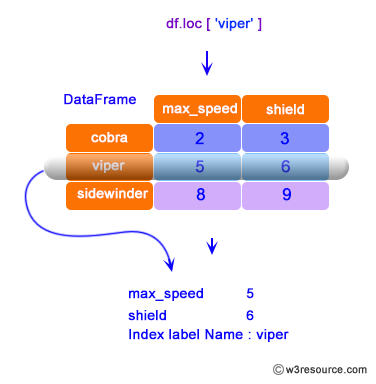

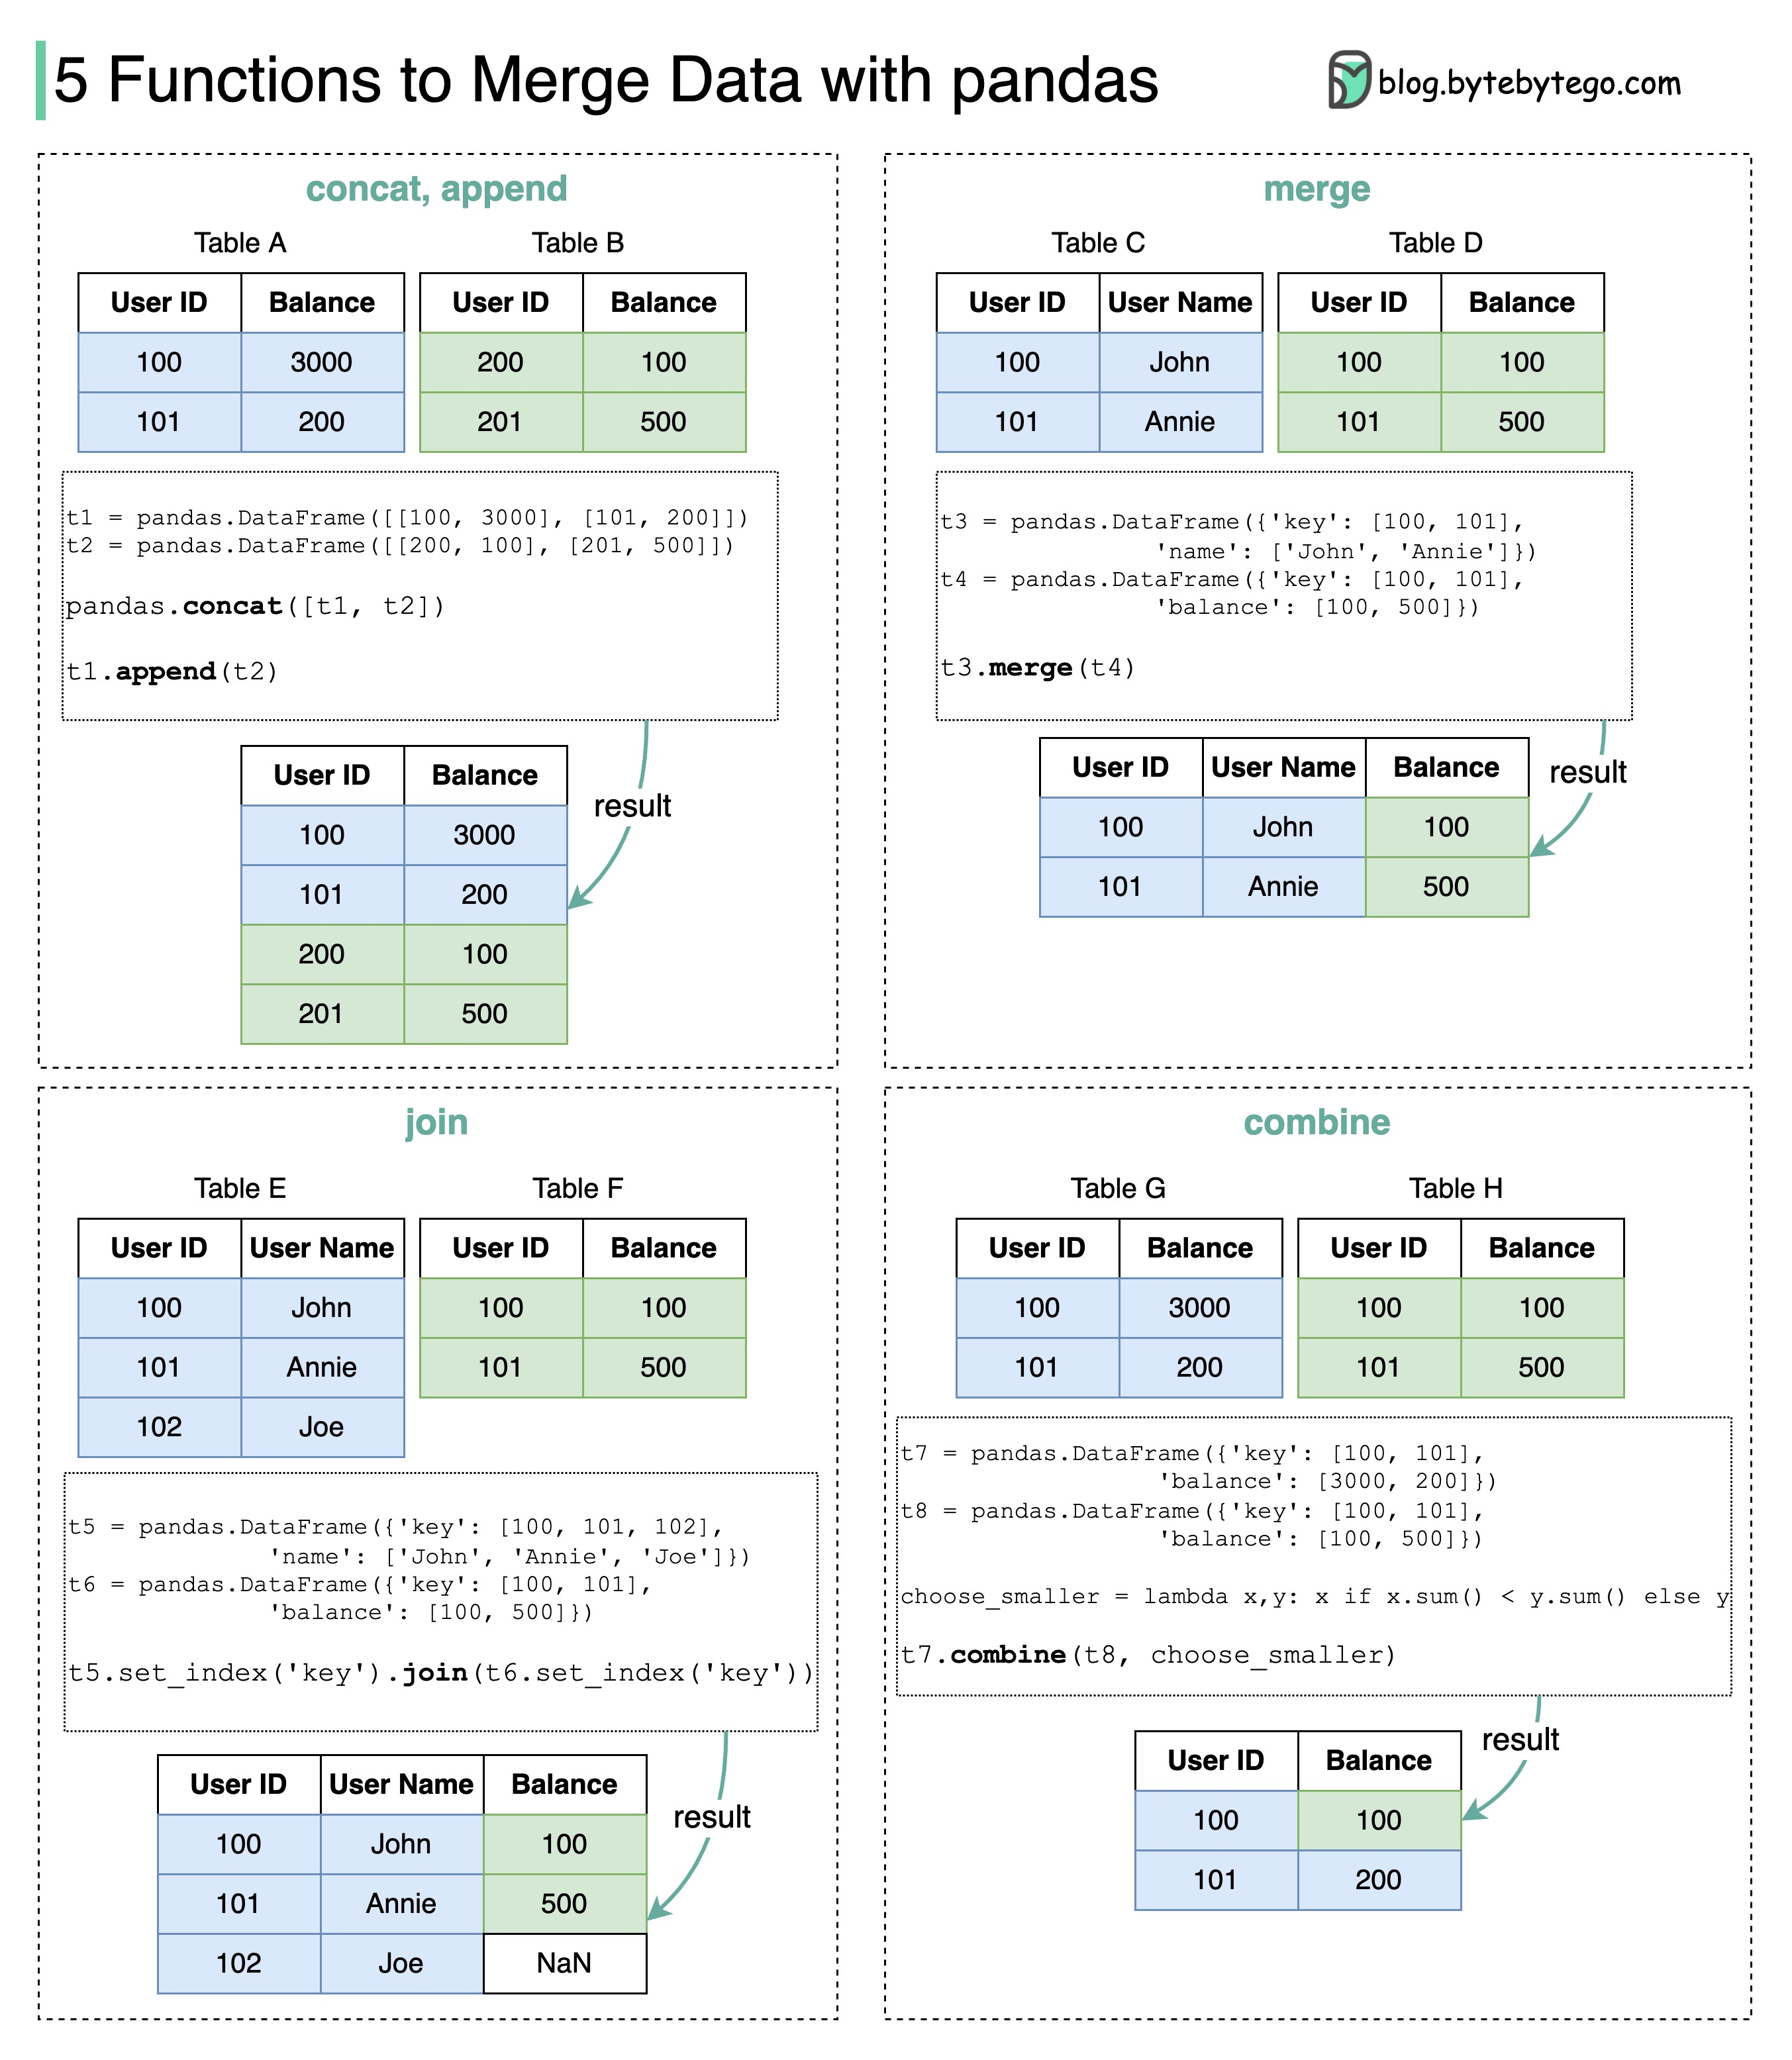

In [ ]:
# np.random.choice(df.index, size=40, replace=False) sorteia 40 números de
# linha diferentes entre si (replace=False = "sem repetição") dentro da tabela
idx_faltantes = np.random.choice(df.index, size=40, replace=False)

# Nas 40 linhas sorteadas, apagamos o valor de "renda_mensal", substituindo
# por np.nan (o "vazio" do pandas) - simulando associados que não informaram a renda
df.loc[idx_faltantes, "renda_mensal"] = np.nan

# df.sample(15, random_state=1) seleciona 15 linhas aleatórias da tabela
# (random_state funciona como a "seed", garantindo reprodutibilidade)
# pd.concat([df, ...]) empilha essas 15 linhas de novo, no final da tabela,
# simulando um erro de cadastro que duplicou alguns associados
# ignore_index=True refaz a numeração das linhas depois de empilhar, para
# não ficar com números de linha repetidos
df = pd.concat([df, df.sample(15, random_state=1)], ignore_index=True)

# Sorteamos 5 linhas diferentes para simular um erro de digitação
idx_outliers = np.random.choice(df.index, size=5, replace=False)

# Multiplicamos o valor da parcela dessas 5 linhas por 15 - simulando,
# por exemplo, alguém que digitou "9750" em vez de "650" no sistema
df.loc[idx_outliers, "valor_parcela"] = df.loc[idx_outliers, "valor_parcela"] * 15

# df.shape devolve (quantidade_de_linhas, quantidade_de_colunas)
# [0] pega só o primeiro valor dessa dupla, ou seja, a quantidade de linhas
print(f"Base com {df.shape[0]} linhas e {df.shape[1]} colunas")

# df.head() mostra, por padrão, as 5 primeiras linhas da tabela - útil para
# conferir visualmente se a tabela está com a cara esperada
df.head()


Base com 815 linhas e 7 colunas


,renda_mensal,tempo_relacionamento_meses,valor_parcela,n_atrasos_ultimos_12m,score_interno,possui_conta_corrente,atrasou_proxima_parcela
0,5394.09,146,89.54,0,729.0,0,0
1,NaN,103,80.00,1,531.0,1,0
2,5665.84,17,962.78,0,445.0,1,0
3,7241.45,14,494.04,0,452.0,0,0
4,NaN,159,155.28,2,512.0,1,0


### Conceito: `.describe()` — estatística descritiva de uma vez só

`.describe()` calcula, para cada coluna numérica, um conjunto de estatísticas-resumo de uma só vez:
- **count**: quantos valores não-vazios existem na coluna.
- **mean**: a média (Seção 3.1).
- **std**: o desvio-padrão — o quanto os valores, em média, se afastam da média (quanto maior, mais espalhados/heterogêneos os dados).
- **min** e **max**: o menor e o maior valor.
- **25%, 50%, 75%**: os **quartis** — dividem os dados ordenados em quatro partes iguais. O quartil de 50% é a própria mediana. A diferença entre o quartil de 75% (chamado **Q3**) e o de 25% (**Q1**) é o **IQR (intervalo interquartil)**, que vamos usar mais adiante para detectar outliers.


In [ ]:
# .describe() calcula as estatísticas-resumo de todas as colunas numéricas
print("Estatísticas descritivas:")
display(df.describe())  # display() mostra a tabela formatada (funciona no Colab/Jupyter)

# .value_counts() conta quantas vezes cada valor aparece em uma coluna
# normalize=True transforma essa contagem em proporção (fração do total, de 0 a 1)
# .round(3) arredonda o resultado para 3 casas decimais
print("\nProporção de atraso na base:")
print(df["atrasou_proxima_parcela"].value_counts(normalize=True).round(3))


Estatísticas descritivas:


,renda_mensal,tempo_relacionamento_meses,valor_parcela,n_atrasos_ultimos_12m,score_interno,possui_conta_corrente,atrasou_proxima_parcela
count,774.000000,815.000000,815.000000,815.000000,815.000000,815.000000,815.000000
mean,4479.805310,89.688344,723.891117,0.722699,603.386503,0.613497,0.233129
std,1719.001889,53.138973,962.591370,0.822988,121.584003,0.487247,0.423083
min,1200.000000,1.000000,80.000000,0.000000,211.000000,0.000000,0.000000
25%,3232.705000,44.000000,441.600000,0.000000,524.500000,0.000000,0.000000
50%,4481.805000,89.000000,652.040000,1.000000,600.000000,1.000000,0.000000
75%,5620.662500,136.500000,881.300000,1.000000,686.000000,1.000000,0.000000
max,11434.920000,179.000000,16624.800000,5.000000,1000.000000,1.000000,1.000000



Proporção de atraso na base:
atrasou_proxima_parcela
0    0.767
1    0.233
Name: proportion, dtype: float64


### Conceito: Valores faltantes e linhas duplicadas

**`.isnull()`** devolve uma tabela do mesmo tamanho, mas com `True` onde havia um valor faltante e `False` onde não havia. Encadeando **`.sum()`** depois, somamos esses `True`/`False` (o Python trata `True` como 1 e `False` como 0) — o resultado é a contagem de faltantes por coluna.

**`.duplicated()`** devolve `True` para cada linha que é uma cópia exata de uma linha anterior. `.sum()` conta quantas são.


In [ ]:
# Para cada coluna, conta quantos valores estão faltando (NaN)
print("Valores faltantes por coluna:")
print(df.isnull().sum())

# Conta quantas linhas inteiras são duplicadas de outra linha já existente
print(f"\nQuantidade de linhas duplicadas: {df.duplicated().sum()}")


Valores faltantes por coluna:
renda_mensal                  41
tempo_relacionamento_meses     0
valor_parcela                  0
n_atrasos_ultimos_12m          0
score_interno                  0
possui_conta_corrente          0
atrasou_proxima_parcela        0
dtype: int64

Quantidade de linhas duplicadas: 15


**Observações da Fase 2 até aqui:** existem valores faltantes em `renda_mensal` (vamos decidir o que fazer na Fase 3); existem linhas duplicadas (provavelmente erro de cadastro); a proporção de atraso está desbalanceada (a maioria não atrasa).


### Visualizando distribuições

**Conceito: Histograma e Boxplot**
- **Histograma**: divide os valores em faixas ("bins") e mostra quantas observações caem em cada faixa — mostra "o formato" de uma distribuição.
- **Boxplot**: resume a distribuição usando os quartis. A caixa vai do Q1 ao Q3 (contém metade dos dados); a linha no meio é a mediana; os "bigodes" vão até 1,5×IQR além da caixa; pontos além disso aparecem marcados — é exatamente o critério que vamos usar como regra estatística para identificar outliers.

**Conceito: `plt.subplots()`**
Cria uma "grade" de gráficos lado a lado. `plt.subplots(1, 2, figsize=(12, 4))` cria 1 linha com 2 gráficos, numa figura de 12x4 polegadas, e devolve duas coisas: `fig` (a figura inteira) e `axes` (uma lista com cada gráfico individual — `axes[0]` é o primeiro, `axes[1]` é o segundo).


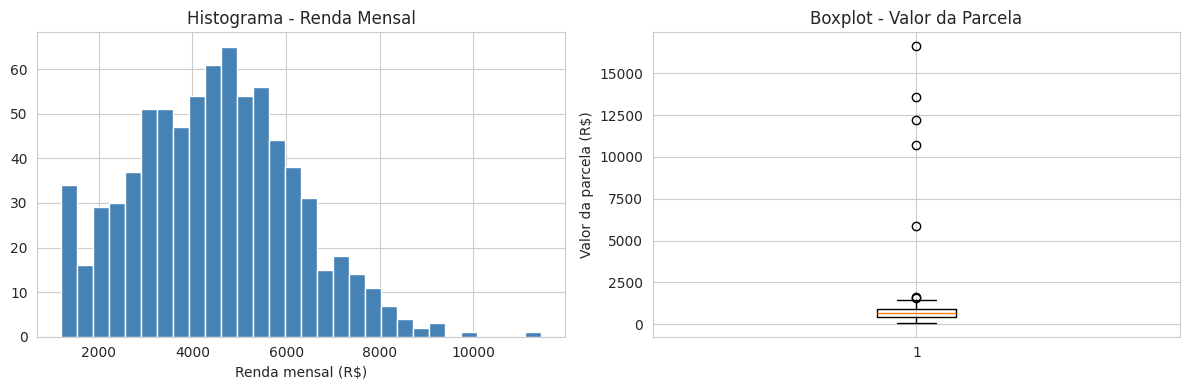

In [ ]:
# Cria uma figura com 1 linha e 2 gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# No primeiro gráfico (axes[0]), desenha um histograma de renda_mensal
# .dropna() remove os valores faltantes antes de desenhar (senão o gráfico dá erro)
# bins=30 divide os valores em 30 faixas
axes[0].hist(df["renda_mensal"].dropna(), bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Histograma - Renda Mensal")  # título do gráfico
axes[0].set_xlabel("Renda mensal (R$)")          # rótulo do eixo horizontal

# No segundo gráfico (axes[1]), desenha um boxplot de valor_parcela
axes[1].boxplot(df["valor_parcela"].dropna(), vert=True)  # vert=True deixa a caixa na vertical
axes[1].set_title("Boxplot - Valor da Parcela")
axes[1].set_ylabel("Valor da parcela (R$)")

plt.tight_layout()  # ajusta os espaçamentos para os textos não ficarem cortados/sobrepostos
plt.show()           # exibe o gráfico na tela


No boxplot, os pontos isolados acima do "bigode" superior são os outliers que introduzimos de propósito — exatamente o tipo de sinal visual que apontaria "algo estranho aconteceu aqui, vale investigar".


### Correlação entre as variáveis numéricas

**Conceito: `.corr()` em uma tabela inteira**
Quando chamamos `.corr()` numa tabela inteira (em vez de duas colunas específicas), o pandas calcula a correlação entre **cada par possível de colunas numéricas** de uma vez, devolvendo uma "matriz de correlação" (uma tabela onde tanto as linhas quanto as colunas são as variáveis).

**Conceito: `sns.heatmap()` (mapa de calor)**
Transforma essa matriz de números em um gráfico colorido, onde cores mais fortes indicam correlação mais próxima de +1 ou -1 — muito mais fácil de interpretar rapidamente do que só olhar números.


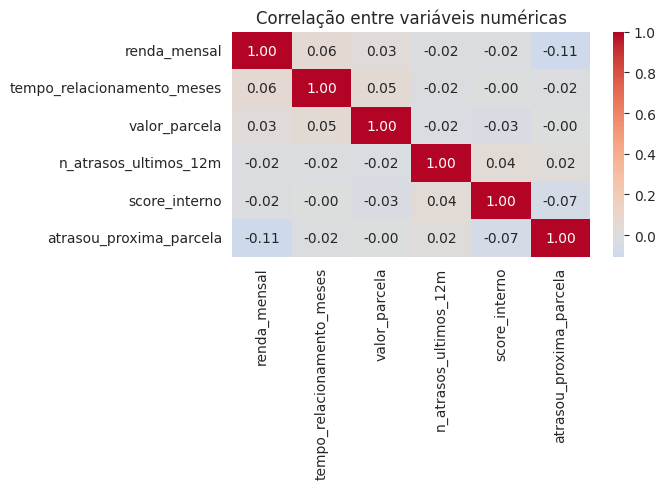

In [ ]:
# .drop(columns=[...]) remove uma coluna antes de calcular a correlação -
# aqui removemos "possui_conta_corrente" porque, apesar de ser numérica (0 ou 1),
# ela representa uma categoria (tem conta / não tem conta), não uma quantidade
# .corr(numeric_only=True) calcula a correlação só entre as colunas numéricas restantes
matriz_corr = df.drop(columns=["possui_conta_corrente"]).corr(numeric_only=True)

plt.figure(figsize=(7, 5))  # cria uma nova figura, com o tamanho especificado

# sns.heatmap desenha o mapa de calor a partir da matriz de correlação
#   annot=True escreve o valor numérico dentro de cada quadradinho
#   fmt=".2f" formata esses números com 2 casas decimais
#   cmap="coolwarm" define a paleta de cores (azul para negativo, vermelho para positivo)
#   center=0 garante que o branco/neutro da paleta fique exatamente no valor 0
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()


**Lendo o mapa de calor:** procurem, na linha ou coluna de `atrasou_proxima_parcela`, quais variáveis têm correlação mais forte com o atraso. Lembrem da armadilha da Seção 3.2: uma correlação moderada aqui é só um **indício** a investigar, não uma prova de causa e efeito.


### Comparando grupos: quem atrasou x quem não atrasou

**Conceito: `.groupby()`**
`.groupby("coluna")` separa a tabela em grupos, um para cada valor distinto daquela coluna (aqui, um grupo para `atrasou_proxima_parcela == 0` e outro para `== 1`). Encadeando uma operação depois (como `.mean()`), ela é calculada **separadamente para cada grupo** — é a forma padrão do pandas de responder perguntas do tipo "como esse grupo se compara àquele outro?".


In [ ]:
# Selecionamos, dentro dos parênteses [ ], só as colunas que nos interessa comparar
# .groupby("atrasou_proxima_parcela") separa a tabela em 2 grupos (0 e 1)
# .mean() calcula a média de cada coluna, separadamente, dentro de cada grupo
# .round(1) arredonda o resultado para 1 casa decimal
comparacao_grupos = df.groupby("atrasou_proxima_parcela")[
    ["renda_mensal", "score_interno", "n_atrasos_ultimos_12m", "tempo_relacionamento_meses"]
].mean().round(1)

# Renomeamos os índices de "0" e "1" para nomes mais legíveis
comparacao_grupos.index = ["Não atrasou", "Atrasou"]

comparacao_grupos


,renda_mensal,score_interno,n_atrasos_ultimos_12m,tempo_relacionamento_meses
Não atrasou,4584.7,607.9,0.7,90.3
Atrasou,4150.7,588.5,0.8,87.8


### Bônus (para quem quiser ir além): um teste estatístico simples

**Conceito: Teste de hipótese e `scipy.stats.ttest_ind()`**
Quando comparamos a média de dois grupos (como acima), surge a pergunta: essa diferença é grande o suficiente para não ser só "sorte" da amostra, ou pode ser ruído aleatório? Um **teste t** ajuda a responder isso.

`stats.ttest_ind(grupo_a, grupo_b, equal_var=False)` compara as médias de dois grupos e devolve dois números: a estatística `t` (quanto maior em módulo, maior a diferença relativa entre os grupos) e o **p-valor**. Por convenção, um p-valor abaixo de 0,05 costuma ser chamado de "estatisticamente significativo" — mas isso **não** significa, sozinho, que a diferença é grande ou importante para o negócio; significância estatística e relevância prática são coisas diferentes.


In [ ]:
# Importamos só o módulo "stats" da biblioteca scipy (que tem funções estatísticas prontas)
from scipy import stats

# Filtramos a tabela: pegamos só as linhas onde atrasou_proxima_parcela == 1,
# e dentro dela, só a coluna "renda_mensal" - .dropna() remove valores faltantes
renda_atrasou = df.loc[df["atrasou_proxima_parcela"] == 1, "renda_mensal"].dropna()

# O mesmo, mas para quem NÃO atrasou (== 0)
renda_nao_atrasou = df.loc[df["atrasou_proxima_parcela"] == 0, "renda_mensal"].dropna()

# Roda o teste t comparando as duas listas de renda
# equal_var=False assume que os dois grupos podem ter variâncias diferentes
# (uma escolha mais segura quando não temos certeza de que são iguais)
resultado_teste = stats.ttest_ind(renda_atrasou, renda_nao_atrasou, equal_var=False)

print(f"Diferença de renda média entre os grupos: R$ {renda_nao_atrasou.mean() - renda_atrasou.mean():,.2f}")
# resultado_teste.statistic é a estatística t calculada pelo teste
print(f"Estatística t: {resultado_teste.statistic:.2f}")
# resultado_teste.pvalue é o p-valor calculado pelo teste
print(f"p-valor: {resultado_teste.pvalue:.4f}")


Diferença de renda média entre os grupos: R$ 434.00
Estatística t: -3.10
p-valor: 0.0021


> ⚠️ Sinalizando incerteza: os números exatos acima dependem dos dados sintéticos gerados. Tratem este bloco como introdução ao **raciocínio** de teste de hipótese; um curso de estatística inferencial trataria as premissas do teste com mais rigor do que cabe aqui.


### 4.3 Fase 3 — Preparação dos Dados (limpeza básica)

Com o que descobrimos, vamos tomar três decisões de limpeza, documentando o motivo de cada uma.

**Conceito: `.fillna()`**
`.fillna(valor)` substitui todos os valores faltantes (`NaN`) de uma coluna por um valor específico — aqui, vamos usar a mediana da própria coluna.


In [ ]:
# Calcula a mediana da coluna renda_mensal (ignorando os valores faltantes,
# que o pandas já ignora automaticamente ao calcular estatísticas)
mediana_renda = df["renda_mensal"].median()

# .fillna(mediana_renda) substitui todo NaN da coluna pelo valor da mediana
# Escolhemos a MEDIANA, e não a média, exatamente pela armadilha da Seção 3.1:
# a mediana é mais robusta a valores extremos, que também existem nessa coluna
df["renda_mensal"] = df["renda_mensal"].fillna(mediana_renda)

print(f"Valores faltantes preenchidos com a mediana: R$ {mediana_renda:,.2f}")

# Conferindo que não sobrou nenhum valor faltante
print(f"Valores faltantes restantes em renda_mensal: {df['renda_mensal'].isnull().sum()}")


Valores faltantes preenchidos com a mediana: R$ 4,481.81
Valores faltantes restantes em renda_mensal: 0


**Conceito: `.drop_duplicates()`**
Remove da tabela as linhas identificadas como duplicadas (mantendo apenas a primeira ocorrência de cada uma).


In [ ]:
# df.shape[0] é a quantidade de linhas ANTES de remover duplicados
linhas_antes = df.shape[0]

# .drop_duplicates() remove as linhas repetidas, mantendo só a primeira ocorrência
df = df.drop_duplicates()

# quantidade de linhas DEPOIS de remover
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")


Linhas antes: 815 | Linhas depois: 800 | Removidas: 15


### Conceito: Regra do IQR para identificar outliers, e `.quantile()`

**`.quantile(fração)`** calcula o valor abaixo do qual aquela fração dos dados está. `.quantile(0.25)` é o Q1 (25% dos dados abaixo dele); `.quantile(0.75)` é o Q3.

A regra estatística mais comum para marcar um valor como "atípico" é:

$$\text{limite inferior} = Q1 - 1{,}5 \times IQR \qquad \text{limite superior} = Q3 + 1{,}5 \times IQR$$

onde $IQR = Q3 - Q1$. Qualquer valor fora desse intervalo é sinalizado como outlier. O multiplicador 1,5 é uma convenção amplamente usada, não uma lei matemática obrigatória.


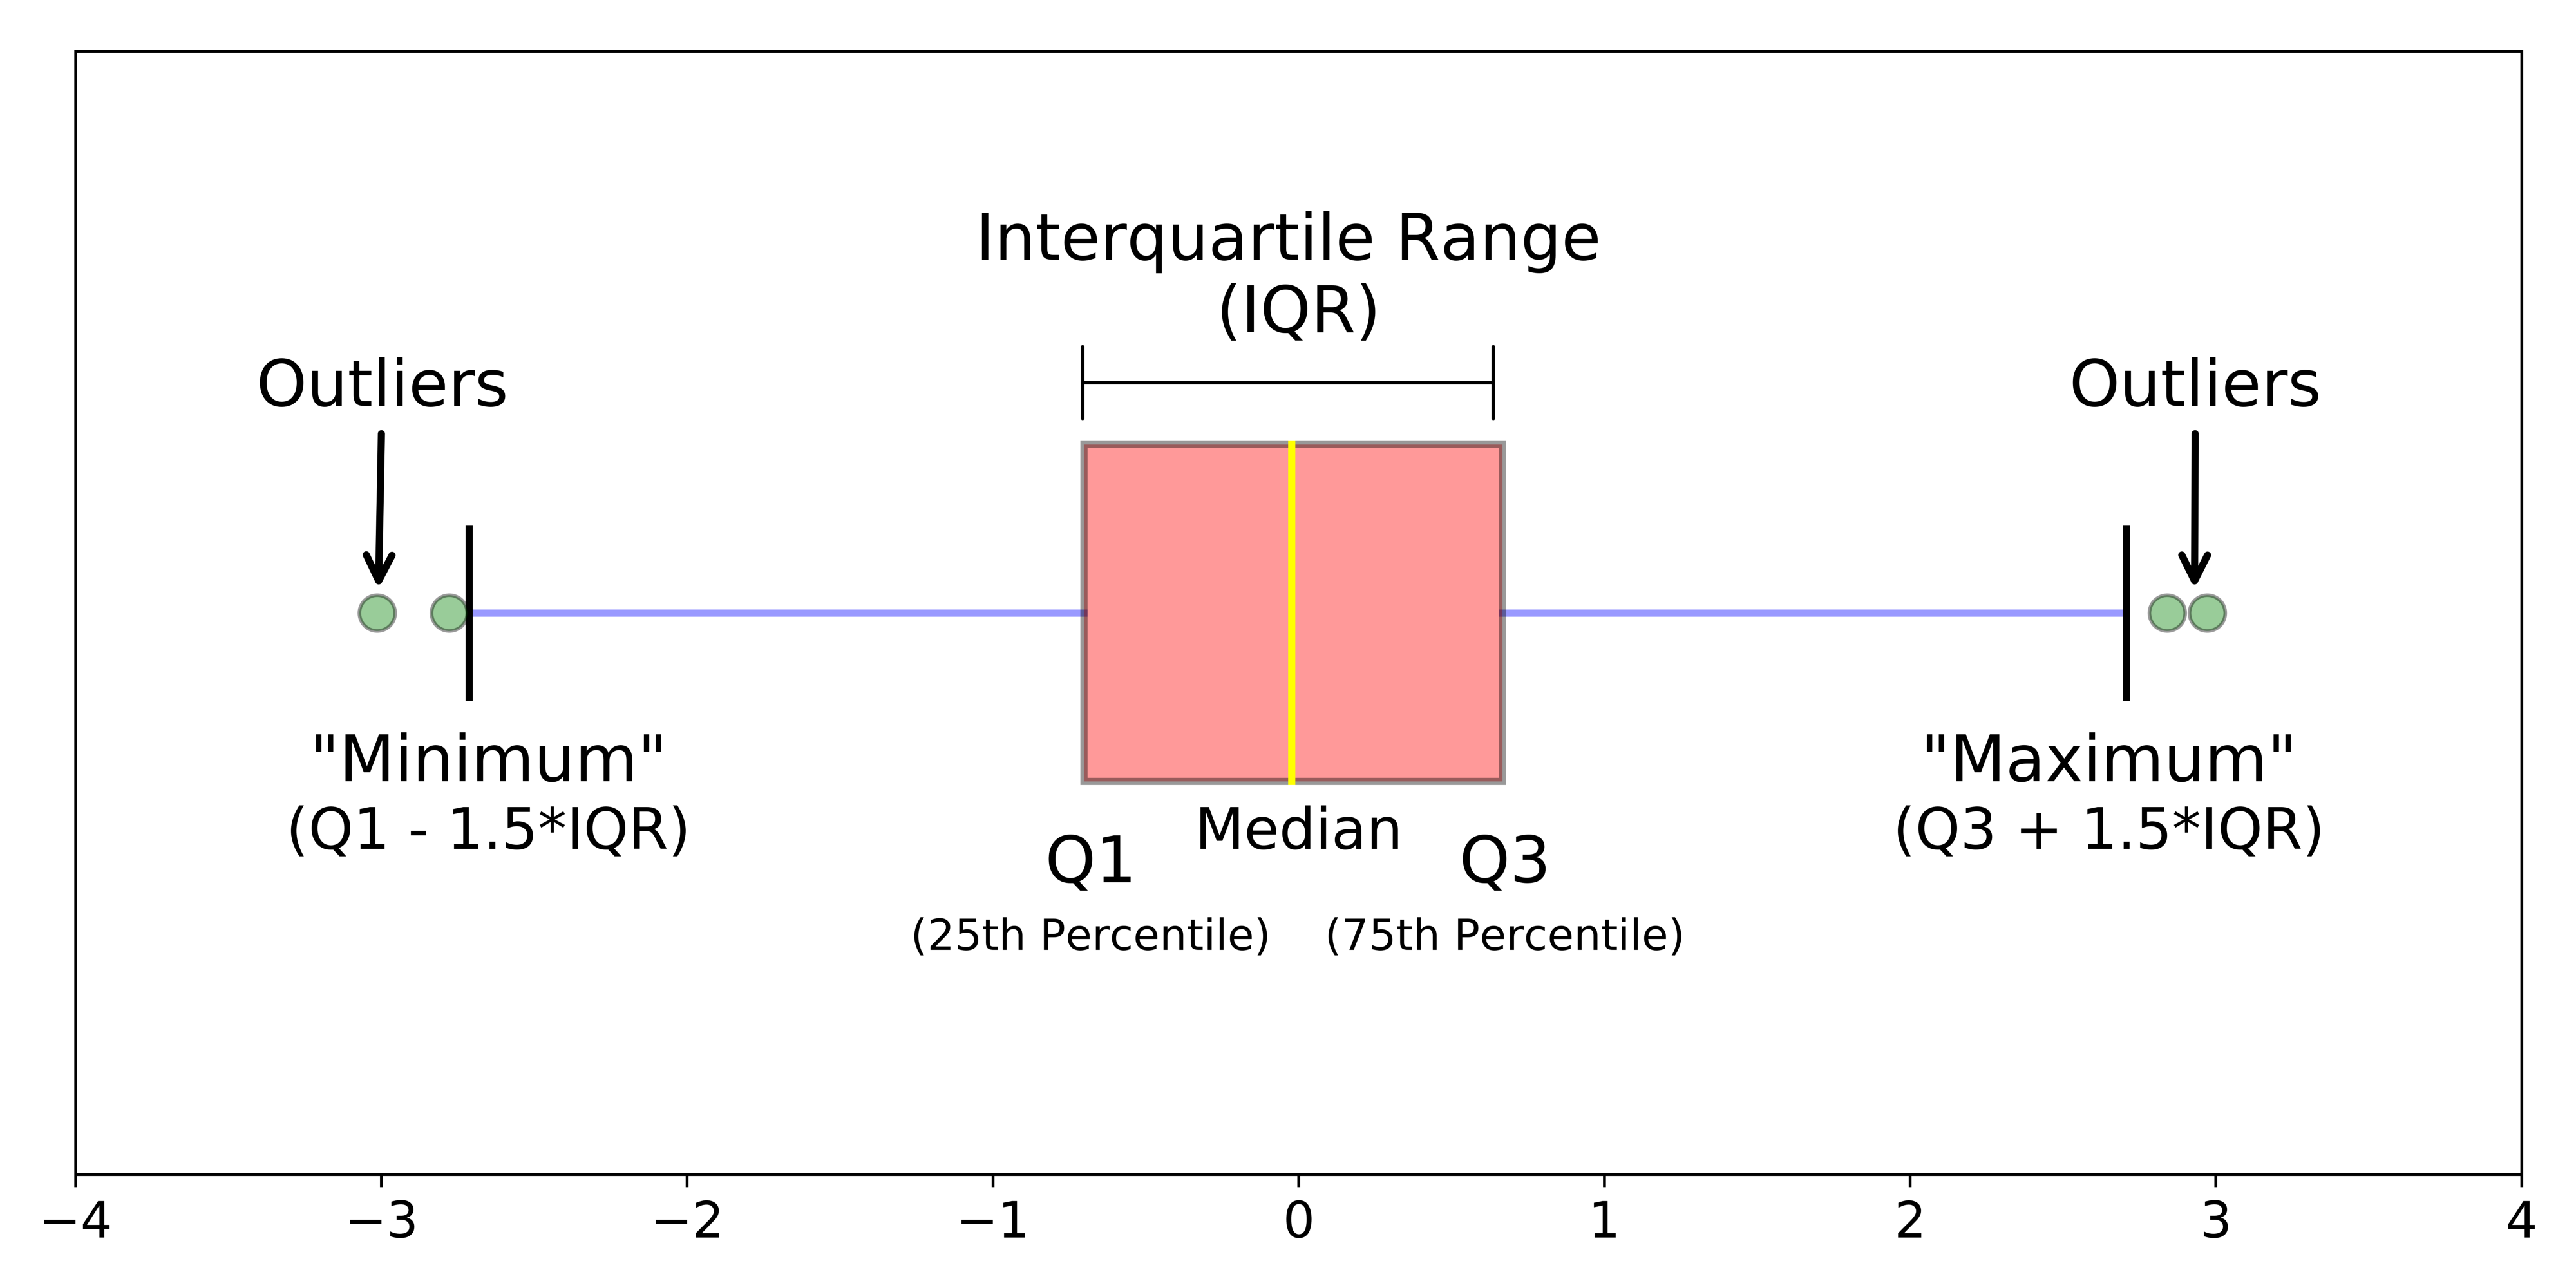

In [ ]:
# Q1 = valor abaixo do qual estão 25% dos dados ordenados
Q1 = df["valor_parcela"].quantile(0.25)

# Q3 = valor abaixo do qual estão 75% dos dados ordenados
Q3 = df["valor_parcela"].quantile(0.75)

# IQR = intervalo interquartil = distância entre Q3 e Q1
IQR = Q3 - Q1

# Calculamos os dois limites da regra estatística
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtramos a tabela: mantemos só as linhas onde valor_parcela está
# ABAIXO do limite inferior OU ACIMA do limite superior (o símbolo | significa "ou")
outliers = df[(df["valor_parcela"] < limite_inferior) | (df["valor_parcela"] > limite_superior)]

print(f"Limite inferior: R$ {limite_inferior:,.2f} | Limite superior: R$ {limite_superior:,.2f}")
print(f"Quantidade de outliers encontrados: {outliers.shape[0]}")

# Mostra só a coluna valor_parcela das linhas identificadas como outlier
outliers[["valor_parcela"]]


Limite inferior: R$ -209.43 | Limite superior: R$ 1,525.71
Quantidade de outliers encontrados: 7


,valor_parcela
366,12231.00
501,16624.80
555,13591.65
617,1576.15
644,5870.85
690,1626.39
718,10702.35


In [ ]:
# Como esses valores (bem acima de qualquer parcela plausível) são
# consistentes com um erro de digitação (multiplicamos por 15 na simulação),
# a decisão é CORRIGIR, não descartar a linha inteira (que tem outras
# informações válidas). Como não temos como recuperar o valor real,
# substituímos pela MEDIANA da coluna - uma escolha conservadora.

# Calcula a mediana atual da coluna (já sem os próprios outliers influenciando muito, já que a mediana é robusta a eles)
mediana_parcela = df["valor_parcela"].median()

# outliers.index guarda os números das linhas identificadas como outlier
# .loc[outliers.index, "valor_parcela"] = ... substitui o valor dessas linhas,
# só na coluna valor_parcela, pelo valor da mediana
df.loc[outliers.index, "valor_parcela"] = mediana_parcela

print(f"Outliers substituídos pela mediana: R$ {mediana_parcela:,.2f}")
print(f"Novo máximo de valor_parcela: R$ {df['valor_parcela'].max():,.2f}")


Outliers substituídos pela mediana: R$ 648.45
Novo máximo de valor_parcela: R$ 1,439.88


> 📌 **Importante:** a decisão de "substituir pela mediana" não é universal — depende do contexto. O que o CRISP-DM exige aqui não é uma resposta pronta, mas o **raciocínio documentado** por trás de cada decisão de limpeza.

### 4.4 O que viria a seguir (Fases 4 a 6) — apenas para situar o projeto

Com a base entendida e limpa, o próximo passo natural seria a **Fase 4 (Modelagem)** — treinar um modelo supervisionado para prever `atrasou_proxima_parcela`. Isso envolveria escolher um algoritmo, preparar as variáveis especificamente para ele e dividir os dados para treino e teste — conteúdo das próximas aulas. Depois viriam a **Fase 5 (Avaliação)** e a **Fase 6 (Implantação)**. O trabalho de hoje é o que torna essas fases futuras possíveis de fazer bem.


## 5. Exercício guiado 1 — Transporte

**Contexto:** uma empresa de transporte coletivo/frota quer entender melhor o comportamento de atrasos de viagens, antes de considerar qualquer modelagem futura.

Preencham as células abaixo seguindo o mesmo raciocínio do exemplo da cooperativa (Fases 1 a 3). Os comentários `# TODO` indicam onde vocês devem completar. **O gabarito completo está na Seção 8**, com todo o código comentado linha a linha, igual fizemos na Seção 4 — tentem resolver antes de olhar.


### 5.1 Fase 1 — Entendimento do Negócio (preencham em texto)

- **Pergunta de negócio:** → escrevam aqui
- **Pergunta traduzida para análise:** → escrevam aqui
- **Tipo de aprendizado que este problema teria, quando chegarmos à modelagem? Por quê?** → escrevam aqui
- **Uma possível armadilha da Seção 3 que vocês precisam vigiar neste problema:** → escrevam aqui


In [ ]:
# 5.2 Fase 2 — Entendimento dos Dados
# Vamos gerar uma base sintética de viagens, com alguns problemas de
# qualidade de propósito. O código segue a MESMA lógica explicada em
# detalhe na Seção 4.2 - revisitem aquela seção se tiverem dúvida sobre
# alguma função usada aqui (np.random.normal, .clip, np.random.choice, etc.)

np.random.seed(7)
n_viagens = 600  # quantidade de viagens fictícias

km_rota = np.random.normal(35, 15, n_viagens).clip(5, 120)          # km percorridos, entre 5 e 120
n_paradas = np.random.randint(3, 40, n_viagens)                      # número de paradas na rota
horario_pico = np.random.choice([0, 1], n_viagens, p=[0.55, 0.45])   # 1 = saiu em horário de pico
chuva_no_dia = np.random.choice([0, 1], n_viagens, p=[0.75, 0.25])   # 1 = choveu no dia da viagem
idade_veiculo_anos = np.random.randint(0, 15, n_viagens).astype(float)  # idade do veículo em anos

# "Pontuação de risco" de atraso, seguindo a mesma lógica da Seção 4.2:
# cada termo aumenta ou diminui a chance de atraso
prob_atraso_viagem = (
    -0.3 - 2.4
    + 0.015 * km_rota
    + 0.02 * n_paradas
    + 0.5 * horario_pico
    + 0.6 * chuva_no_dia
    + 0.04 * idade_veiculo_anos
)
prob_atraso_viagem = 1 / (1 + np.exp(-prob_atraso_viagem))  # transforma em probabilidade (0 a 1)
atraso_viagem = np.random.binomial(1, np.clip(prob_atraso_viagem, 0, 1))  # sorteia o resultado final

# Monta a tabela
df_transporte = pd.DataFrame({
    "km_rota": km_rota.round(1),
    "n_paradas": n_paradas,
    "horario_pico": horario_pico,
    "chuva_no_dia": chuva_no_dia,
    "idade_veiculo_anos": idade_veiculo_anos,
    "atraso_viagem": atraso_viagem,
})

# Introduzindo problemas de qualidade, igual fizemos na Seção 4.2:
idx_falt = np.random.choice(df_transporte.index, size=25, replace=False)  # sorteia 25 linhas
df_transporte.loc[idx_falt, "idade_veiculo_anos"] = np.nan                # apaga a idade do veículo nelas

df_transporte = pd.concat([df_transporte, df_transporte.sample(10, random_state=2)], ignore_index=True)  # duplica 10 linhas

idx_out = np.random.choice(df_transporte.index, size=4, replace=False)     # sorteia 4 linhas
df_transporte.loc[idx_out, "km_rota"] = df_transporte.loc[idx_out, "km_rota"] * 6  # simula erro de digitação (km x6)

df_transporte.head()


In [ ]:
# TODO (Fase 2 continuação): explorem a base como fizemos na Seção 4.
# Cada uma das linhas abaixo é uma sugestão - descomentem uma de cada vez
# (removam o "#" do início) e rodem para ver o resultado, ou escrevam por conta própria.
#
# df_transporte.describe()
# df_transporte["atraso_viagem"].value_counts(normalize=True)
# df_transporte.isnull().sum()
# df_transporte.duplicated().sum()
#
# Depois, tentem reproduzir (adaptando os nomes de coluna) o histograma + boxplot
# da Seção 4.2, e a matriz de correlação com sns.heatmap.

# Escrevam o código de vocês aqui:



In [ ]:
# TODO (Fase 3 — Preparação dos Dados)
# Sigam o mesmo padrão explicado linha a linha na Seção 4.3:
#   1. Calculem a mediana de "idade_veiculo_anos" e usem .fillna() para
#      preencher os valores faltantes
#   2. Usem .drop_duplicates() para remover as linhas duplicadas
#   3. Calculem Q1, Q3 e IQR de "km_rota" (.quantile(0.25) e .quantile(0.75)),
#      encontrem os outliers pela regra dos limites, e decidam o que fazer
#      com eles (substituir pela mediana, remover, investigar) - justifiquem

# Escrevam o código de vocês aqui:



### 5.3 Fechamento do exercício (discussão em texto, sem código)

- O que a análise exploratória revelou sobre o problema de atrasos que vocês não sabiam antes de olhar os dados?
- Se a empresa fosse avançar para a Fase 4 (Modelagem) no futuro, que tipo de aprendizado faria sentido, com base no que vimos hoje?


## 6. Exercício guiado 2 — Saúde

**Contexto:** um hospital/rede de clínicas quer entender melhor o perfil de pacientes crônicos antes de desenhar programas de acompanhamento diferenciados. Gabarito na Seção 8.


### 6.1 Fase 1 — Entendimento do Negócio (preencham em texto)

- **Pergunta de negócio:** → escrevam aqui
- **Pergunta traduzida para análise:** → escrevam aqui
- **Se, no futuro, quisessem agrupar pacientes por perfil sem um rótulo pronto, que tipo de aprendizado seria esse (conexão com a Aula 1)?** → escrevam aqui
- **Um risco ético/regulatório a considerar (dado de saúde é sensível — LGPD):** → escrevam aqui


In [ ]:
# 6.2 Fase 2 — Entendimento dos Dados (mesma lógica da Seção 4.2)
np.random.seed(21)
n_pacientes = 500

idade = np.random.normal(58, 14, n_pacientes).clip(25, 95)
imc = np.random.normal(27, 5, n_pacientes).clip(16, 45)                        # Índice de Massa Corporal
n_consultas_ano = np.random.poisson(4, n_pacientes).astype(float)              # consultas médicas por ano
n_internacoes_2anos = np.random.poisson(0.4, n_pacientes)                      # internações nos últimos 2 anos
adesao_tratamento_pct = np.random.normal(70, 20, n_pacientes).clip(0, 100)     # % de adesão ao tratamento

df_saude = pd.DataFrame({
    "idade": idade.round(0),
    "imc": imc.round(1),
    "n_consultas_ano": n_consultas_ano,
    "n_internacoes_2anos": n_internacoes_2anos,
    "adesao_tratamento_pct": adesao_tratamento_pct.round(1),
})

# Problemas de qualidade, de propósito (mesma lógica da Seção 4.2):
idx_falt = np.random.choice(df_saude.index, size=20, replace=False)
df_saude.loc[idx_falt, "n_consultas_ano"] = np.nan

df_saude = pd.concat([df_saude, df_saude.sample(8, random_state=3)], ignore_index=True)

idx_out = np.random.choice(df_saude.index, size=3, replace=False)
df_saude.loc[idx_out, "imc"] = df_saude.loc[idx_out, "imc"] * 2.5

df_saude.head()


In [ ]:
# TODO (Fase 2 continuação): explorem a base (describe, histogramas, boxplots,
# valores faltantes, duplicados, matriz de correlação) - sigam o mesmo roteiro
# explicado passo a passo na Seção 4.2

# Escrevam o código de vocês aqui:



In [ ]:
# TODO (Fase 3 — Preparação dos Dados)
#   1. Tratem os valores faltantes em "n_consultas_ano" (mediana + .fillna())
#   2. Removam duplicados (.drop_duplicates())
#   3. Identifiquem e tratem outliers em "imc" usando a regra do IQR
#      (mesmos passos da Seção 4.3)

# Escrevam o código de vocês aqui:



### 6.3 Fechamento do exercício (discussão em texto, sem código)

- Olhando as estatísticas descritivas e a distribuição das variáveis, vocês conseguem imaginar 2 ou 3 "perfis" diferentes de paciente, mesmo sem rodar nenhum algoritmo? Descrevam-nos.
- Por que esse problema se encaixaria melhor em aprendizado não supervisionado do que supervisionado?


## 7. Exercício guiado 3 — Indústria / Cooperativa Agroindustrial

**Contexto:** representando "outras" cooperativas e setores (agroindustrial, industrial), vamos explorar dados simulados de sensores de um equipamento, pensando em manutenção. Gabarito na Seção 8.


### 7.1 Fase 1 — Entendimento do Negócio (preencham em texto)

- **Pergunta de negócio:** → escrevam aqui
- **Pergunta traduzida para análise:** → escrevam aqui
- **Tipo de aprendizado que esse problema teria, no futuro?** → escrevam aqui


In [ ]:
# 7.2 Fase 2 — Entendimento dos Dados (mesma lógica da Seção 4.2)
np.random.seed(99)
n_leituras = 500

temperatura_c = np.random.normal(65, 12, n_leituras).clip(30, 120)
vibracao_mm_s = np.random.normal(3.5, 1.5, n_leituras).clip(0.2, 12)
horas_uso_desde_manutencao = np.random.randint(0, 2000, n_leituras).astype(float)
pressao_bar = np.random.normal(6, 1.2, n_leituras).clip(2, 12)

prob_falha = (
    -2.0 - 3.3
    + 0.03 * temperatura_c
    + 0.35 * vibracao_mm_s
    + 0.0012 * horas_uso_desde_manutencao
    - 0.05 * pressao_bar
)
prob_falha = 1 / (1 + np.exp(-prob_falha))
falha_proximos_7_dias = np.random.binomial(1, np.clip(prob_falha, 0, 1))

df_industria = pd.DataFrame({
    "temperatura_c": temperatura_c.round(1),
    "vibracao_mm_s": vibracao_mm_s.round(2),
    "horas_uso_desde_manutencao": horas_uso_desde_manutencao,
    "pressao_bar": pressao_bar.round(2),
    "falha_proximos_7_dias": falha_proximos_7_dias,
})

# Problemas de qualidade, de propósito:
idx_falt = np.random.choice(df_industria.index, size=15, replace=False)
df_industria.loc[idx_falt, "horas_uso_desde_manutencao"] = np.nan

idx_out = np.random.choice(df_industria.index, size=3, replace=False)
df_industria.loc[idx_out, "vibracao_mm_s"] = df_industria.loc[idx_out, "vibracao_mm_s"] * 5

df_industria.head()


In [ ]:
# TODO (Fases 2 e 3 - Entendimento e Preparação dos Dados)
# Sigam o mesmo processo dos exercícios anteriores e da Seção 4:
#   Fase 2: describe(), proporção de falhas, faltantes, boxplot de "vibracao_mm_s",
#           matriz de correlação
#   Fase 3: tratem os valores faltantes em "horas_uso_desde_manutencao" e os
#           outliers em "vibracao_mm_s" (regra do IQR)

# Escrevam o código de vocês aqui (podem usar quantas células quiserem):



### 7.3 Fechamento do exercício (discussão em texto, sem código)

- Qual variável parece ter a relação mais forte com `falha_proximos_7_dias`, pela matriz de correlação? Isso já é uma prova de causa, ou só um indício (Seção 3.2)?
- Numa planta industrial, quem deveria ser informado quando a análise exploratória revela um padrão de risco como esse — mesmo antes de existir um modelo treinado?


## 8. Gabaritos

> 🔓 **Só abram esta seção depois de tentar resolver os exercícios das Seções 5, 6 e 7.** O código abaixo está comentado linha a linha, exatamente como na Seção 4 — usem para conferir o raciocínio de vocês, não para só copiar.


### 8.1 Gabarito — Exercício 1 (Transporte)

**Fase 1 (exemplo de resposta):**
- Pergunta de negócio: reduzir reclamações de passageiros/clientes por atraso.
- Pergunta traduzida para análise: quais fatores operacionais parecem estar mais associados a viagens atrasadas?
- Tipo de aprendizado futuro: **supervisionado** — existe um histórico rotulado (`atraso_viagem`).
- Armadilha a vigiar: correlação não implica causalidade.


In [ ]:
# GABARITO — Fase 2 (Transporte)

# .describe() calcula média, desvio-padrão, quartis etc. de cada coluna numérica
print("Estatísticas descritivas:")
display(df_transporte.describe())

# proporção de viagens com e sem atraso
print("\nProporção de viagens com atraso:")
print(df_transporte["atraso_viagem"].value_counts(normalize=True).round(3))

# quantidade de valores faltantes por coluna
print("\nValores faltantes:")
print(df_transporte.isnull().sum())

# quantidade de linhas duplicadas
print(f"\nLinhas duplicadas: {df_transporte.duplicated().sum()}")

# histograma e boxplot de km_rota, lado a lado (mesma lógica da Seção 4.2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_transporte["km_rota"].dropna(), bins=25, color="steelblue", edgecolor="white")
axes[0].set_title("Histograma - km da rota")
axes[1].boxplot(df_transporte["km_rota"].dropna())
axes[1].set_title("Boxplot - km da rota")
plt.tight_layout()
plt.show()

# matriz de correlação com mapa de calor
plt.figure(figsize=(6, 4))
sns.heatmap(df_transporte.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação - Transporte")
plt.tight_layout()
plt.show()

# comparação de médias entre viagens com e sem atraso
print(df_transporte.groupby("atraso_viagem")[["km_rota", "n_paradas", "idade_veiculo_anos"]].mean().round(1))


In [ ]:
# GABARITO — Fase 3 (Transporte)

# 1) Preenchendo valores faltantes com a mediana
mediana_idade_veic = df_transporte["idade_veiculo_anos"].median()
df_transporte["idade_veiculo_anos"] = df_transporte["idade_veiculo_anos"].fillna(mediana_idade_veic)

# 2) Removendo linhas duplicadas
df_transporte = df_transporte.drop_duplicates()

# 3) Identificando outliers em km_rota pela regra do IQR
Q1_t = df_transporte["km_rota"].quantile(0.25)
Q3_t = df_transporte["km_rota"].quantile(0.75)
IQR_t = Q3_t - Q1_t
lim_inf_t = Q1_t - 1.5 * IQR_t
lim_sup_t = Q3_t + 1.5 * IQR_t

outliers_t = df_transporte[(df_transporte["km_rota"] < lim_inf_t) | (df_transporte["km_rota"] > lim_sup_t)]
print(f"Outliers encontrados em km_rota: {outliers_t.shape[0]}")

# Substituindo os outliers pela mediana
mediana_km = df_transporte["km_rota"].median()
df_transporte.loc[outliers_t.index, "km_rota"] = mediana_km
print(f"Outliers substituídos pela mediana: {mediana_km:.1f} km")


**Fechamento (exemplo de resposta):** a análise mostrou que viagens atrasadas tendem a ter rotas mais longas e mais paradas — um indício (não uma prova) de que esses fatores merecem atenção operacional. Um futuro modelo seria supervisionado, já que existe histórico rotulado.


### 8.2 Gabarito — Exercício 2 (Saúde)

**Fase 1 (exemplo de resposta):**
- Pergunta de negócio: melhorar a eficácia dos programas de acompanhamento de pacientes crônicos.
- Pergunta traduzida para análise: existem perfis distintos de pacientes que sugerem diferentes formas de acompanhamento?
- Tipo de aprendizado futuro: **não supervisionado** — não existe um rótulo pronto de "grupo correto".
- Risco: dados de saúde são sensíveis (LGPD) — é preciso garantir anonimização/uso autorizado.


In [ ]:
# GABARITO — Fase 2 (Saúde)
print(df_saude.describe())
print("\nValores faltantes:")
print(df_saude.isnull().sum())
print(f"\nLinhas duplicadas: {df_saude.duplicated().sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_saude["imc"].dropna(), bins=25, color="seagreen", edgecolor="white")
axes[0].set_title("Histograma - IMC")
axes[1].boxplot(df_saude["imc"].dropna())
axes[1].set_title("Boxplot - IMC")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(df_saude.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação - Saúde")
plt.tight_layout()
plt.show()


In [ ]:
# GABARITO — Fase 3 (Saúde)
mediana_consultas = df_saude["n_consultas_ano"].median()
df_saude["n_consultas_ano"] = df_saude["n_consultas_ano"].fillna(mediana_consultas)

df_saude = df_saude.drop_duplicates()

Q1_s = df_saude["imc"].quantile(0.25)
Q3_s = df_saude["imc"].quantile(0.75)
IQR_s = Q3_s - Q1_s
lim_inf_s = Q1_s - 1.5 * IQR_s
lim_sup_s = Q3_s + 1.5 * IQR_s

outliers_s = df_saude[(df_saude["imc"] < lim_inf_s) | (df_saude["imc"] > lim_sup_s)]
print(f"Outliers encontrados em imc: {outliers_s.shape[0]}")

mediana_imc = df_saude["imc"].median()
df_saude.loc[outliers_s.index, "imc"] = mediana_imc


**Fechamento (exemplo de resposta):** é razoável imaginar um grupo de pacientes mais jovens e com boa adesão, outro de pacientes mais velhos com mais internações, e um terceiro intermediário — mas isso é só uma hipótese até validarmos com uma técnica de agrupamento de verdade (aula futura). Por não existir rótulo de "grupo correto", é um problema de aprendizado **não supervisionado**.


### 8.3 Gabarito — Exercício 3 (Indústria/Agroindustrial)

**Fase 1 (exemplo de resposta):**
- Pergunta de negócio: reduzir paradas não planejadas de equipamentos críticos.
- Pergunta traduzida para análise: quais leituras de sensores parecem mais associadas a falhas registradas?
- Tipo de aprendizado futuro: **supervisionado** — há um rótulo histórico (`falha_proximos_7_dias`).


In [ ]:
# GABARITO — Fases 2 e 3 (Indústria)
print(df_industria.describe())
print("\nValores faltantes:")
print(df_industria.isnull().sum())

plt.figure(figsize=(5, 4))
plt.boxplot(df_industria["vibracao_mm_s"].dropna())
plt.title("Boxplot - Vibração (mm/s)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(df_industria.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação - Indústria")
plt.tight_layout()
plt.show()

mediana_horas = df_industria["horas_uso_desde_manutencao"].median()
df_industria["horas_uso_desde_manutencao"] = df_industria["horas_uso_desde_manutencao"].fillna(mediana_horas)

Q1_i = df_industria["vibracao_mm_s"].quantile(0.25)
Q3_i = df_industria["vibracao_mm_s"].quantile(0.75)
IQR_i = Q3_i - Q1_i
lim_inf_i = Q1_i - 1.5 * IQR_i
lim_sup_i = Q3_i + 1.5 * IQR_i

outliers_i = df_industria[(df_industria["vibracao_mm_s"] < lim_inf_i) | (df_industria["vibracao_mm_s"] > lim_sup_i)]
print(f"Outliers encontrados em vibracao_mm_s: {outliers_i.shape[0]}")

mediana_vib = df_industria["vibracao_mm_s"].median()
df_industria.loc[outliers_i.index, "vibracao_mm_s"] = mediana_vib


**Fechamento (exemplo de resposta):** tipicamente `vibracao_mm_s` e `temperatura_c` aparecem com correlação mais evidente com `falha_proximos_7_dias` — mas isso é um indício estatístico, não uma prova de causa. A equipe de manutenção deveria ser informada desse padrão desde já, mesmo sem modelo treinado — a análise exploratória, sozinha, já gera valor de negócio.


## 9. Fechamento — Checklist e por que isso importa

### Checklist do que praticamos hoje (Fases 1 a 3)
- [ ] **Entendimento do Negócio:** a pergunta foi escrita de forma clara?
- [ ] **Entendimento dos Dados:** calculamos estatísticas descritivas, visualizamos distribuições, calculamos correlações — sem confundir correlação com causalidade?
- [ ] **Preparação dos Dados:** identificamos e tratamos valores faltantes, duplicados e outliers, documentando o motivo de cada decisão?

### Por que isso importa
Antes de qualquer modelo existir, é a análise exploratória que decide se um projeto de IA tem chance de dar certo. O trabalho de hoje — estatística descritiva, visualização, identificação de problemas de qualidade — é o que torna a modelagem futura confiável.


